# CAMM Hackathon 12: Real-Time Drift Correction

In this challenge, the image is acquired line-by-line while the sample drifts. Your goal is to estimate that drift online and correct the image as the scan arrives.

## Task

Build a method that, for each newly acquired scan line:

- estimates the current drift
- updates the reconstructed image in real time
- produces a corrected final image

Keep the solution simple and fast enough to run during acquisition.

## What is provided

This notebook gives you:

- one STEM image to use as source data
- several synthetic drift models
- a simulator that corrupts the image line-by-line
- a streaming generator that mimics real-time acquisition

You only need to focus on the correction strategy.

## 1. Setup

In [1]:
# Install dependencies (Colab / fresh environment)
!pip -q install SciFiReaders gdown


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.7/135.7 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 128.0/128.0 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 41.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.9/69.9 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 150.0/150.0 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 42.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 55.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.1/104.1 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 69.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 519.0/519.0 kB 26.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 151.9/151.9 

In [2]:
from pathlib import Path

file_id = "16Oavm1j0gcGR2mPXWCAqLfVm1MSngy1Z"
filename = "1547 STEM 1.45 Mx HAADF 0001.emd"

if not Path(filename).exists():
    !gdown {file_id} -O "{filename}"
else:
    print(f"Using existing file: {filename}")


Downloading...
From: https://drive.google.com/uc?id=16Oavm1j0gcGR2mPXWCAqLfVm1MSngy1Z
To: /content/1547 STEM 1.45 Mx HAADF 0001.emd
100% 8.85M/8.85M [00:00<00:00, 178MB/s]


## 2. Imports

In [3]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import clear_output
from SciFiReaders import EMDReader


## 3. Drift Models

These helper functions generate different drift trajectories. They are provided for testing and benchmarking.

In [4]:
#@title drift models




def drift_constant_velocity(
    n_lines: int,
    vx: float = 0.02,
    vy: float = 0.0,
    dt: float = 1.0,
    u0x: float = 0.0,
    u0y: float = 0.0,
):
    """
    Constant-velocity drift.

    Model:
        ux(t) = u0x + vx * t
        uy(t) = u0y + vy * t

    Parameters
    ----------
    n_lines : int
        Number of scan lines.
    vx, vy : float
        Drift velocity in pixels per unit time.
    dt : float
        Time step per line.
    u0x, u0y : float
        Initial drift offsets in pixels.

    Returns
    -------
    t : ndarray, shape (n_lines,)
        Time axis.
    ux, uy : ndarray, shape (n_lines,)
        Drift trajectory in pixels.
    """
    t = np.arange(n_lines, dtype=float) * dt
    ux = u0x + vx * t
    uy = u0y + vy * t
    return t, ux, uy


def drift_constant_velocity_random_walk(
    n_lines: int,
    vx0: float = 0.02,
    vy0: float = 0.0,
    sigma_ax: float = 0.002,
    sigma_ay: float = 0.002,
    dt: float = 1.0,
    u0x: float = 0.0,
    u0y: float = 0.0,
    seed: int | None = None,
):
    """
    Constant-velocity model with random-walk velocity.

    State evolution:
        vx[t+1] = vx[t] + eps_x
        vy[t+1] = vy[t] + eps_y
        ux[t+1] = ux[t] + vx[t] * dt
        uy[t+1] = uy[t] + vy[t] * dt

    This is a very good default Kalman-style drift model.

    Parameters
    ----------
    n_lines : int
        Number of scan lines.
    vx0, vy0 : float
        Initial velocities in pixels per unit time.
    sigma_ax, sigma_ay : float
        Std of velocity perturbation per step.
    dt : float
        Time step per line.
    u0x, u0y : float
        Initial offsets.
    seed : int or None
        Random seed.

    Returns
    -------
    t, ux, uy : ndarray
        Time axis and drift trajectories.
    """
    rng = np.random.default_rng(seed)

    t = np.arange(n_lines, dtype=float) * dt
    ux = np.zeros(n_lines, dtype=float)
    uy = np.zeros(n_lines, dtype=float)
    vx = np.zeros(n_lines, dtype=float)
    vy = np.zeros(n_lines, dtype=float)

    ux[0], uy[0] = u0x, u0y
    vx[0], vy[0] = vx0, vy0

    for i in range(1, n_lines):
        vx[i] = vx[i - 1] + rng.normal(0.0, sigma_ax)
        vy[i] = vy[i - 1] + rng.normal(0.0, sigma_ay)

        ux[i] = ux[i - 1] + vx[i - 1] * dt
        uy[i] = uy[i - 1] + vy[i - 1] * dt

    return t, ux, uy


def drift_creep_log(
    n_lines: int,
    ax: float = 2.0,
    ay: float = 0.5,
    tau_x: float = 20.0,
    tau_y: float = 20.0,
    dt: float = 1.0,
    u0x: float = 0.0,
    u0y: float = 0.0,
):
    """
    Logarithmic creep-like drift.

    Model:
        ux(t) = u0x + ax * log(1 + t / tau_x)
        uy(t) = u0y + ay * log(1 + t / tau_y)

    Useful as a simple AFM-like creep surrogate.

    Parameters
    ----------
    ax, ay : float
        Drift amplitudes in pixels.
    tau_x, tau_y : float
        Characteristic time scales.

    Returns
    -------
    t, ux, uy : ndarray
    """
    t = np.arange(n_lines, dtype=float) * dt
    ux = u0x + ax * np.log1p(t / tau_x)
    uy = u0y + ay * np.log1p(t / tau_y)
    return t, ux, uy


def drift_creep_exponential(
    n_lines: int,
    ax: float = 2.0,
    ay: float = 0.5,
    tau_x: float = 30.0,
    tau_y: float = 30.0,
    dt: float = 1.0,
    u0x: float = 0.0,
    u0y: float = 0.0,
):
    """
    Exponential relaxation / creep model.

    Model:
        ux(t) = u0x + ax * (1 - exp(-t / tau_x))
        uy(t) = u0y + ay * (1 - exp(-t / tau_y))

    Good when drift is strongest at the beginning and saturates.

    Returns
    -------
    t, ux, uy : ndarray
    """
    t = np.arange(n_lines, dtype=float) * dt
    ux = u0x + ax * (1.0 - np.exp(-t / tau_x))
    uy = u0y + ay * (1.0 - np.exp(-t / tau_y))
    return t, ux, uy


def drift_oscillatory(
    n_lines: int,
    ax: float = 0.5,
    ay: float = 0.2,
    freq_x: float = 0.02,
    freq_y: float = 0.03,
    phase_x: float = 0.0,
    phase_y: float = 0.0,
    dt: float = 1.0,
    u0x: float = 0.0,
    u0y: float = 0.0,
):
    """
    Oscillatory drift model.

    Model:
        ux(t) = u0x + ax * sin(2*pi*freq_x*t + phase_x)
        uy(t) = u0y + ay * sin(2*pi*freq_y*t + phase_y)

    Useful as a toy vibration / periodic instability component.

    Parameters
    ----------
    ax, ay : float
        Oscillation amplitudes in pixels.
    freq_x, freq_y : float
        Frequencies in cycles per unit time.

    Returns
    -------
    t, ux, uy : ndarray
    """
    t = np.arange(n_lines, dtype=float) * dt
    ux = u0x + ax * np.sin(2 * np.pi * freq_x * t + phase_x)
    uy = u0y + ay * np.sin(2 * np.pi * freq_y * t + phase_y)
    return t, ux, uy


def drift_composite(
    n_lines: int,
    dt: float = 1.0,
    linear_vx: float = 0.01,
    linear_vy: float = 0.0,
    creep_ax: float = 1.0,
    creep_ay: float = 0.3,
    creep_tau_x: float = 25.0,
    creep_tau_y: float = 25.0,
    osc_ax: float = 0.1,
    osc_ay: float = 0.05,
    osc_freq_x: float = 0.02,
    osc_freq_y: float = 0.015,
    phase_x: float = 0.0,
    phase_y: float = 0.0,
    noise_sigma_x: float = 0.02,
    noise_sigma_y: float = 0.02,
    u0x: float = 0.0,
    u0y: float = 0.0,
    seed: int | None = None,
):
    """
    Composite drift model:
    linear trend + creep + oscillation + small random noise.

    This is often the most realistic general-purpose simulator.

    Returns
    -------
    t, ux, uy : ndarray
    """
    rng = np.random.default_rng(seed)
    t = np.arange(n_lines, dtype=float) * dt

    linear_x = linear_vx * t
    linear_y = linear_vy * t

    creep_x = creep_ax * (1.0 - np.exp(-t / creep_tau_x))
    creep_y = creep_ay * (1.0 - np.exp(-t / creep_tau_y))

    osc_x = osc_ax * np.sin(2 * np.pi * osc_freq_x * t + phase_x)
    osc_y = osc_ay * np.sin(2 * np.pi * osc_freq_y * t + phase_y)

    noise_x = rng.normal(0.0, noise_sigma_x, size=n_lines)
    noise_y = rng.normal(0.0, noise_sigma_y, size=n_lines)

    ux = u0x + linear_x + creep_x + osc_x + noise_x
    uy = u0y + linear_y + creep_y + osc_y + noise_y

    return t, ux, uy

### Visualize example drift trajectories

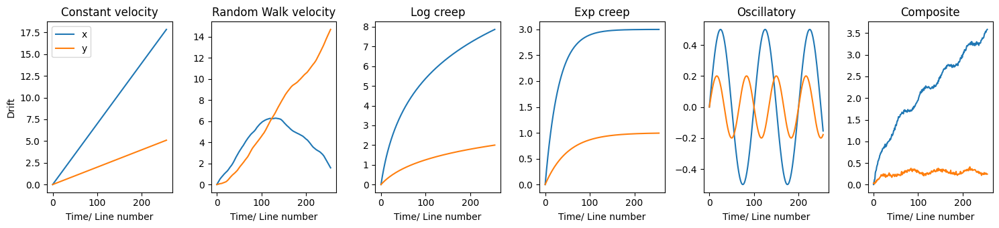

In [5]:
import matplotlib.pyplot as plt

n_lines = 256

fig, axes = plt.subplots(1, 6, figsize=(15, 3.5))

# --- 1. Constant velocity ---
t, ux1, uy1 = drift_constant_velocity(n_lines, vx=0.07, vy=0.02)
axes[0].plot(t, ux1, label='x')
axes[0].plot(t, uy1, label='y')
axes[0].legend()
axes[0].set_title("Constant velocity")

# --- 2. Random walk velocity ---
t, ux2, uy2 = drift_constant_velocity_random_walk(
    n_lines,
    vx0=0.07,
    vy0=0.01,
    sigma_ax=0.005,
    sigma_ay=0.005,
    seed=0
)
axes[1].plot(t, ux2, label='x')
axes[1].plot(t, uy2, label='y')
axes[1].set_title("Random Walk velocity")

# --- 3. Log creep ---
t, ux3, uy3 = drift_creep_log(n_lines, ax=3.0, ay=1.0, tau_x=20, tau_y=40)
axes[2].plot(t, ux3)
axes[2].plot(t, uy3)
axes[2].set_title("Log creep")

# --- 4. Exp creep ---
t, ux4, uy4 = drift_creep_exponential(n_lines, ax=3.0, ay=1.0, tau_x=30, tau_y=50)
axes[3].plot(t, ux4)
axes[3].plot(t, uy4)
axes[3].set_title("Exp creep")

# --- 5. Oscillatory ---
t, ux5, uy5 = drift_oscillatory(
    n_lines, ax=0.5, ay=0.2, freq_x=0.01, freq_y=0.015
)
axes[4].plot(t, ux5)
axes[4].plot(t, uy5)
axes[4].set_title("Oscillatory")

# --- 6. Composite ---
t, ux6, uy6 = drift_composite(n_lines, seed=2)
axes[5].plot(t, ux6)
axes[5].plot(t, uy6)
axes[5].set_title("Composite")

# --- formatting ---
for ax in axes:
    #ax.set_xticks([])   # cleaner
    #ax.set_yticks([])
    ax.set_xlabel("Time/ Line number")


#axes[0].set_xlabel("Time")
axes[0].set_ylabel("Drift")


fig.tight_layout()
plt.show()

## 4. Load the Source Image

In [6]:
emd_path = Path("1547 STEM 1.45 Mx HAADF 0001.emd")
reader = EMDReader(str(emd_path))
data = reader.read()

haadf_data = data["Channel_000"][:]
print("Loaded image shape:", haadf_data.shape)


Loaded image shape: (2048, 2048)


## 5. Drift Simulator

This helper creates a corrupted scan from a clean image and returns the ground-truth drift used to generate it.

In [7]:
import numpy as np
from dataclasses import dataclass
from typing import Callable, Any
from scipy.ndimage import map_coordinates


@dataclass
class DriftSimulationResult:
    cropped_reference: np.ndarray
    cropped_corrupted: np.ndarray
    t: np.ndarray
    ux: np.ndarray
    uy: np.ndarray
    model_name: str
    model_kwargs: dict[str, Any]
    crop_bbox: tuple[int, int, int, int]  # y0, y1, x0, x1


def simulate_scan_drift_cropped_output(
    image: np.ndarray,
    model: str | Callable[..., tuple[np.ndarray, np.ndarray, np.ndarray]],
    model_kwargs: dict | None = None,
    out_shape: tuple[int, int] | None = None,
    dt: float = 1.0,
    interpolation_order: int = 1,
    extra_margin: int = 2,
    drift_models: dict[str, Callable] | None = None,
):
    """
    Simulate line-by-line drift, but return only a central cropped output.
    Important: drifted sampling is performed from the FULL image, not from a pre-cropped image.

    Parameters
    ----------
    image : np.ndarray
        Input 2D image.
    model : str or callable
        Drift model name or callable returning (t, ux, uy).
    model_kwargs : dict or None
        Parameters for drift model.
    out_shape : tuple[int, int] or None
        Output cropped shape (H, W). If None, use the maximal safe central crop.
    dt : float
        Time step per line.
    interpolation_order : int
        Interpolation order for map_coordinates.
    extra_margin : int
        Extra safety pixels beyond max drift.
    drift_models : dict or None
        Optional registry of named drift models.

    Returns
    -------
    DriftSimulationResult
    """
    if image.ndim != 2:
        raise ValueError("image must be a 2D array")

    H, W = image.shape
    model_kwargs = {} if model_kwargs is None else dict(model_kwargs)

    if drift_models is None:
        drift_models = {
            "constant_velocity": drift_constant_velocity,
            "random_walk_velocity": drift_constant_velocity_random_walk,
            "creep_log": drift_creep_log,
            "creep_exponential": drift_creep_exponential,
            "oscillatory": drift_oscillatory,
            "composite": drift_composite,
        }

    # resolve model
    if isinstance(model, str):
        if model not in drift_models:
            raise ValueError(f"Unknown model '{model}'. Available: {list(drift_models)}")
        model_fn = drift_models[model]
        model_name = model
    else:
        model_fn = model
        model_name = getattr(model, "__name__", "custom_model")

    # determine number of lines
    if out_shape is not None:
        out_h, out_w = out_shape
        model_kwargs["n_lines"] = out_h
    else:
        model_kwargs.setdefault("n_lines", H)

    model_kwargs.setdefault("dt", dt)

    # generate drift
    t, ux, uy = model_fn(**model_kwargs)
    ux = np.asarray(ux, dtype=float)
    uy = np.asarray(uy, dtype=float)

    if ux.shape != uy.shape:
        raise ValueError("ux and uy must have the same shape")

    n_lines = len(ux)

    # safe crop margins
    margin_x = int(np.ceil(np.max(np.abs(ux)))) + extra_margin
    margin_y = int(np.ceil(np.max(np.abs(uy)))) + extra_margin

    safe_h = H - 2 * margin_y
    safe_w = W - 2 * margin_x

    if safe_h <= 0 or safe_w <= 0:
        raise ValueError("Image too small for requested drift magnitude")

    if out_shape is None:
        out_h = min(n_lines, safe_h)
        out_w = safe_w
    else:
        out_h, out_w = out_shape
        if n_lines != out_h:
            raise ValueError(
                f"len(ux)={n_lines} must match out_shape[0]={out_h}"
            )
        if out_h > safe_h or out_w > safe_w:
            raise ValueError(
                f"Requested out_shape={out_shape} exceeds safe crop {(safe_h, safe_w)}"
            )

    # define central crop in the reference image
    y0 = (H - out_h) // 2
    x0 = (W - out_w) // 2
    y1 = y0 + out_h
    x1 = x0 + out_w

    cropped_reference = image[y0:y1, x0:x1]

    # simulate corrupted cropped output using FULL image coordinates
    cropped_corrupted = np.zeros((out_h, out_w), dtype=float)
    x_local = np.arange(out_w, dtype=float)

    for i in range(out_h):
        y_full = np.full(out_w, y0 + i + uy[i], dtype=float)
        x_full = x0 + x_local + ux[i]

        cropped_corrupted[i] = map_coordinates(
            image,
            [y_full, x_full],
            order=interpolation_order,
            mode="nearest",
        )

    return DriftSimulationResult(
        cropped_reference=cropped_reference,
        cropped_corrupted=cropped_corrupted,
        t=t[:out_h],
        ux=ux[:out_h],
        uy=uy[:out_h],
        model_name=model_name,
        model_kwargs=model_kwargs,
        crop_bbox=(y0, y1, x0, x1),
    )

## 6. Create a Sample Drifted Image

Use this synthetic example to develop and debug your method.

In [51]:
result = simulate_scan_drift_cropped_output(
    image=haadf_data,
    model="random_walk_velocity",
    model_kwargs={
        "vx0": 0.13,
        "vy0": 0.17,
        "sigma_ax": 0.03,
        "sigma_ay": 0.03,
        "seed": 3,
    },
    out_shape=(256, 256),
    interpolation_order=1,
    extra_margin=3,
)

img_ref = result.cropped_reference
img_cor = result.cropped_corrupted
ux = result.ux
uy = result.uy


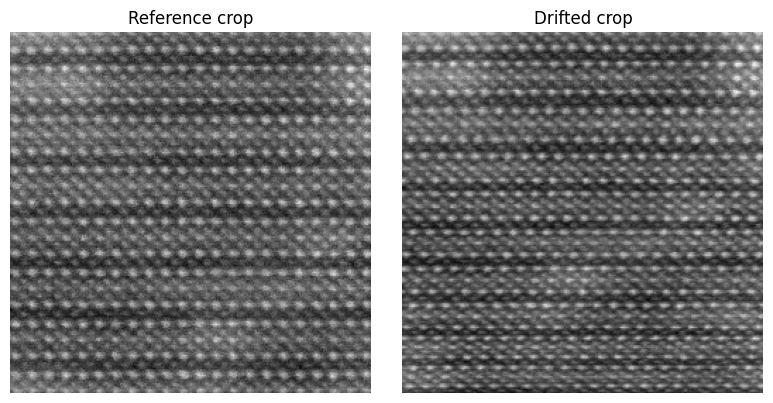

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(img_ref, cmap="gray")
axes[0].set_title("Reference crop")
axes[0].axis("off")

axes[1].imshow(img_cor, cmap="gray")
axes[1].set_title("Drifted crop")
axes[1].axis("off")

plt.tight_layout()
plt.show()


## 7. Streaming Interface

The function below yields the scan one line at a time, like a live acquisition stream.

In [14]:
from typing import Callable, Any, Iterator

def corrupted_image_scan_stream(
    corrupted_image: np.ndarray,
    true_ux: np.ndarray | None = None,
    true_uy: np.ndarray | None = None,
) -> Iterator[dict]:
    """
    Yield scan progress line-by-line.

    Returns a dict containing:
    - current line index
    - current line
    - partial image acquired so far
    - optional true drift
    """
    if corrupted_image.ndim != 2:
        raise ValueError("corrupted_image must be a 2D array")

    H, W = corrupted_image.shape
    partial = np.full((H, W), np.nan, dtype=float)

    for i in range(H):
        partial[i] = corrupted_image[i]

        item = {
            "line_index": i,
            "line": corrupted_image[i].copy(),
            "partial_image": partial.copy(),
        }

        if true_ux is not None:
            item["ux_true"] = float(true_ux[i])
        if true_uy is not None:
            item["uy_true"] = float(true_uy[i])

        yield item

## 8. Your Code

Suggested outputs:

- corrected image
- estimated drift versus line index
- short note on your approach and assumptions

In [20]:
import numpy as np


def estimate_shift(line_prev: np.ndarray, line_curr: np.ndarray) -> tuple[float, float]:
    """
    Estimate the lateral shift between two adjacent scan lines via
    cross-correlation with subpixel refinement.

    Parameters
    ----------
    line_prev : 1D array, line n-1
    line_curr : 1D array, line n

    Returns
    -------
    shift : float
        Estimated shift in pixels (positive = line_curr shifted right)
    confidence : float
        Peak-to-sidelobe ratio of the CC peak; higher = more reliable
    """
    n = len(line_prev)

    # Normalize each line to zero mean, unit std to remove DC and gain effects
    def _norm(x):
        x = x - x.mean()
        std = x.std()
        return x / std if std > 1e-10 else x

    a = _norm(line_prev)
    b = _norm(line_curr)

    # Full cross-correlation via FFT
    cc = np.fft.irfft(np.fft.rfft(a) * np.conj(np.fft.rfft(b)), n=n)
    cc = np.fft.fftshift(cc) / n          # center so zero-lag is at index n//2
    lags = np.arange(n) - n // 2

    # Restrict search range to ±max_shift pixels to avoid wrap-around artefacts
    max_shift = n // 4
    mask = np.abs(lags) <= max_shift
    cc_masked = cc * mask

    peak_idx = np.argmax(cc_masked)
    peak_val = cc[peak_idx]

    # Subpixel refinement: parabolic interpolation around the peak
    if 1 <= peak_idx <= n - 2:
        y0, y1, y2 = cc[peak_idx - 1], cc[peak_idx], cc[peak_idx + 1]
        denom = 2 * (2 * y1 - y0 - y2)
        subpixel_offset = (y0 - y2) / denom if abs(denom) > 1e-12 else 0.0
    else:
        subpixel_offset = 0.0

    shift = lags[peak_idx] + subpixel_offset

    # Confidence: ratio of peak to mean of remaining CC values
    sidelobe = (cc_masked.sum() - peak_val) / max(1, mask.sum() - 1)
    confidence = peak_val / (abs(sidelobe) + 1e-10)

    return float(shift), float(confidence)

In [23]:
stream = corrupted_image_scan_stream(img_cor)
frame = next(stream)
line_n = frame['line']

In [24]:
#your code
line_nminus1 = line_n
frame = next(stream)
line_n = frame['line']

shift, confidence = estimate_shift(line_nminus1, line_curr = line_n)


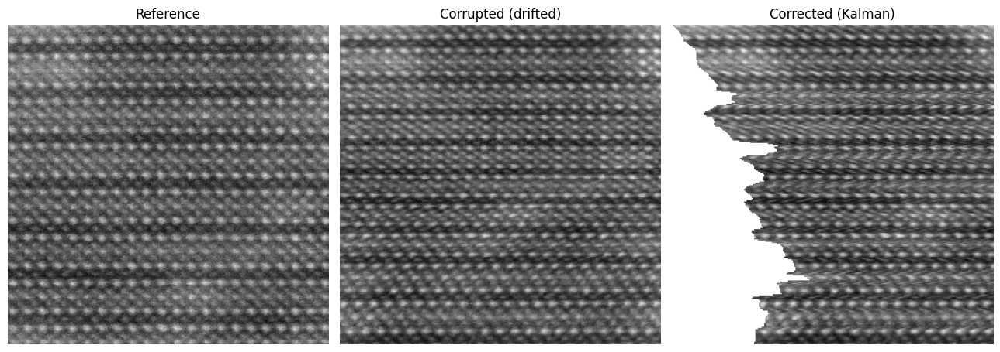

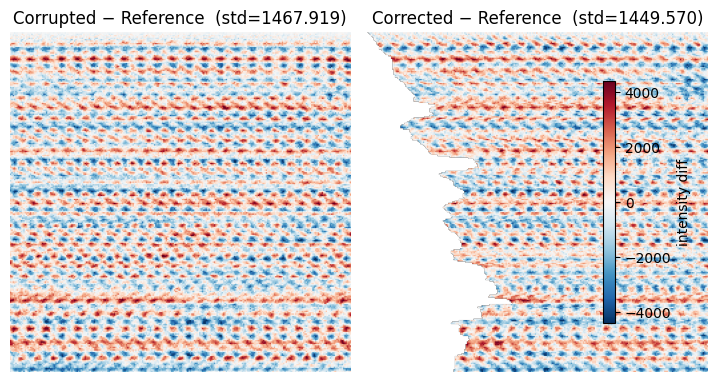

In [31]:
from scipy.ndimage import map_coordinates

def apply_drift_correction(corrupted_image, drift_x):
    """
    Shift each line of corrupted_image by -drift_x[n] using subpixel interpolation.

    Parameters
    ----------
    corrupted_image : 2D array (n_lines, n_cols)
    drift_x : 1D array (n_lines,) — estimated drift per line in pixels

    Returns
    -------
    corrected : 2D array, same shape
    """
    H, W = corrupted_image.shape
    corrected = np.full((H, W), np.nan)
    cols = np.arange(W, dtype=float)

    for n in range(H):
        shifted_cols = cols + drift_x[n]          # sample from shifted position
        # only interpolate within bounds
        valid = (shifted_cols >= 0) & (shifted_cols <= W - 1)
        coords = np.array([np.full(W, n, dtype=float), shifted_cols])
        row = map_coordinates(corrupted_image, coords, order=1, mode='constant', cval=np.nan)
        row[~valid] = np.nan
        corrected[n] = row

    return corrected


img_corrected = apply_drift_correction(img_cor, d_hat)

# --- plot ---
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))

axes[0].imshow(img_ref, cmap='gray')
axes[0].set_title('Reference')
axes[0].axis('off')

axes[1].imshow(img_cor, cmap='gray')
axes[1].set_title('Corrupted (drifted)')
axes[1].axis('off')

axes[2].imshow(img_corrected, cmap='gray')
axes[2].set_title('Corrected (Kalman)')
axes[2].axis('off')

plt.tight_layout()
plt.show()

# --- difference images ---
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))

diff_before = img_cor - img_ref
diff_after  = np.where(np.isnan(img_corrected), np.nan, img_corrected - img_ref)
vmax = np.nanstd(diff_before) * 3

axes[0].imshow(diff_before, cmap='RdBu_r', vmin=-vmax, vmax=vmax)

axes[0].axis('off')

im = axes[1].imshow(diff_after, cmap='RdBu_r', vmin=-vmax, vmax=vmax)

axes[1].axis('off')

# with:
axes[0].set_title(f'Corrupted − Reference  (std={float(np.nanstd(diff_before)):.3f})')
axes[1].set_title(f'Corrected − Reference  (std={float(np.nanstd(diff_after)):.3f})')

plt.colorbar(im, ax=axes.tolist(), shrink=0.7, label='intensity diff')
plt.subplots_adjust(wspace=0.05)

In [32]:
import numpy as np
from scipy.optimize import curve_fit


def estimate_shift(line_prev, line_curr, max_shift=None):
    """
    Estimate lateral shift between two adjacent scan lines using
    phase correlation with Gaussian peak fitting.

    Phase correlation whitens the spectrum so all frequencies contribute
    equally — gives a sharper, more localized peak than standard CC.
    Gaussian fit on the peak returns a proper uncertainty (sigma) that
    feeds directly into the Kalman filter as sqrt(R).

    Parameters
    ----------
    line_prev, line_curr : 1D arrays
    max_shift : int, optional — search range in pixels, defaults to len/4

    Returns
    -------
    shift      : float — estimated shift in pixels
    shift_std  : float — uncertainty (Gaussian sigma), use as sqrt(R)
    confidence : float — peak amplitude / noise floor, higher = better
    """
    n = len(line_prev)
    if max_shift is None:
        max_shift = n // 4

    def _norm(x):
        x = x - x.mean()
        s = x.std()
        return x / s if s > 1e-10 else x

    a, b = _norm(line_prev), _norm(line_curr)

    # --- phase correlation ---
    Fa, Fb = np.fft.rfft(a), np.fft.rfft(b)
    cross  = Fa * np.conj(Fb)
    denom  = np.abs(cross)
    cross_norm = np.where(denom > 1e-10, cross / denom, 0.0)
    pc = np.fft.irfft(cross_norm, n=n)
    pc = np.fft.fftshift(pc)                 # centre at zero-lag
    lags = np.arange(n) - n // 2

    # restrict to ±max_shift
    mask     = np.abs(lags) <= max_shift
    pc_search = np.where(mask, pc, -np.inf)
    peak_idx  = int(np.argmax(pc_search))

    # noise floor: median of non-peak region (robust to outliers)
    noise_region = pc[mask]
    noise_floor  = np.median(np.abs(noise_region))
    confidence   = float(pc[peak_idx] / (noise_floor + 1e-10))

    # --- Gaussian fit around the peak ---
    half_w = 6    # fit window half-width in pixels
    lo = max(peak_idx - half_w, 0)
    hi = min(peak_idx + half_w + 1, n)

    fit_lags = lags[lo:hi].astype(float)
    fit_vals = pc[lo:hi]

    shift_int = float(lags[peak_idx])   # integer fallback
    shift_std = float(max_shift)        # fallback: max uncertainty

    try:
        def gaussian(x, center, sigma, amp, offset):
            return amp * np.exp(-0.5 * ((x - center) / sigma) ** 2) + offset

        p0 = [shift_int, 2.0, float(pc[peak_idx]), float(noise_floor)]
        bounds = (
            [shift_int - half_w, 0.3,  0.0,  -np.inf],
            [shift_int + half_w, half_w, np.inf, np.inf],
        )
        popt, pcov = curve_fit(gaussian, fit_lags, fit_vals,
                               p0=p0, bounds=bounds, maxfev=400)
        shift     = float(popt[0])
        shift_std = float(popt[1])          # sigma → sqrt(R) for Kalman

        # reject fit if covariance exploded (poor fit)
        if np.sqrt(pcov[0, 0]) > half_w:
            shift     = shift_int
            shift_std = float(max_shift)

    except (RuntimeError, ValueError):
        # fit failed: fall back to integer peak
        shift     = shift_int
        shift_std = float(max_shift)

    return shift, shift_std, confidence


# --- smoke test ---
rng = np.random.default_rng(0)
n_test = 256
true_shift = 3.7

line_a = np.sin(np.linspace(0, 4 * np.pi, n_test)) + 0.3 * rng.standard_normal(n_test)
i = int(true_shift); frac = true_shift - i
line_b = (1 - frac) * np.roll(line_a, i) + frac * np.roll(line_a, i + 1)
line_b += 0.1 * rng.standard_normal(n_test)

shift, shift_std, confidence = estimate_shift(line_a, line_b)
print(f"True shift:      {true_shift:.3f} px")
print(f"Estimated shift: {shift:.3f} px  ±{shift_std:.3f} px  (confidence {confidence:.1f})")
print(f"Error:           {abs(shift - true_shift):.4f} px")

True shift:      3.700 px
Estimated shift: -4.000 px  ±64.000 px  (confidence 30.3)
Error:           7.7000 px


/tmp/ipykernel_21367/3078979181.py:33: RuntimeWarning: invalid value encountered in divide
  pc     = np.fft.irfft(np.where(denom > 1e-10, cross / denom, 0.0), n=n)


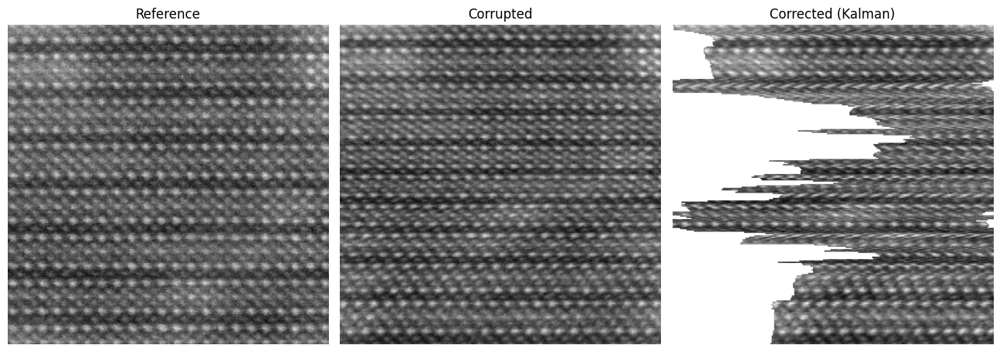

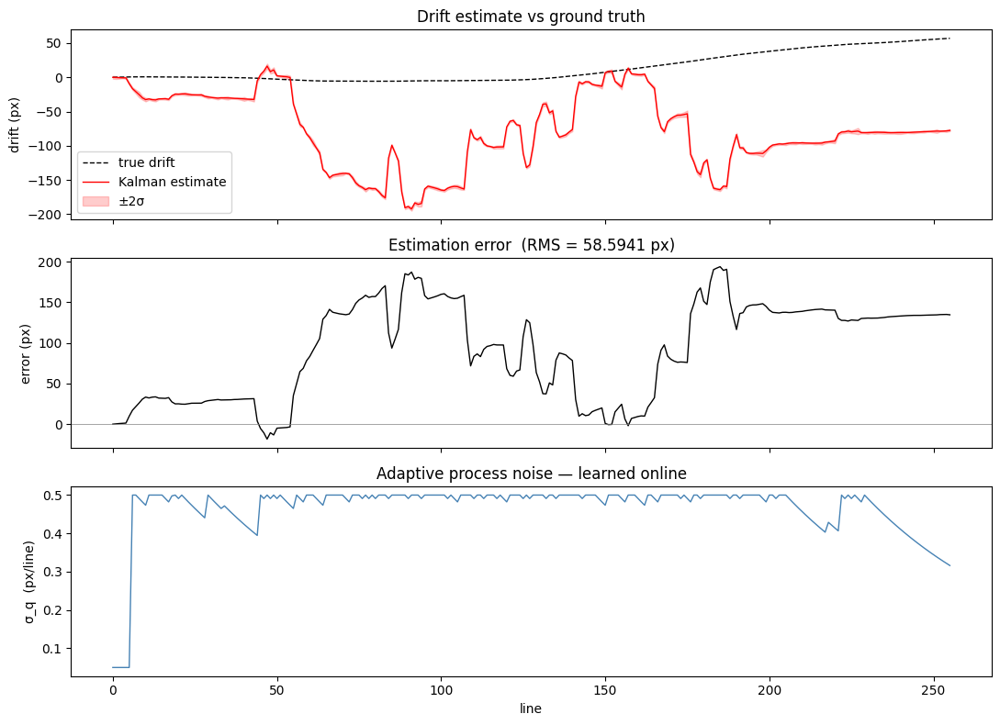

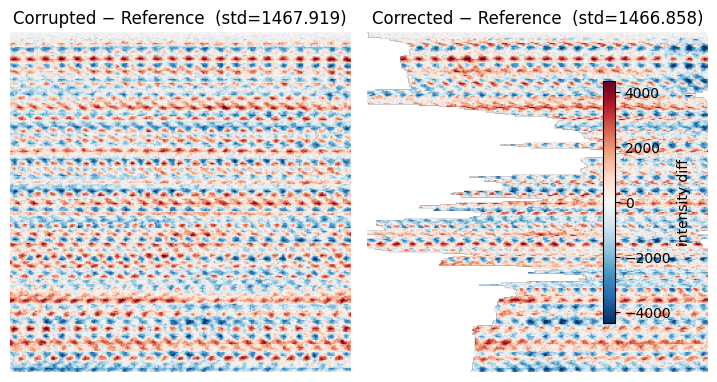

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates


# ── 1. SHIFT ESTIMATOR ────────────────────────────────────────────────────────

def estimate_shift(line_prev, line_curr, max_shift=None):
    """
    Phase correlation + Gaussian peak fit.

    Returns
    -------
    shift      : float — estimated shift in pixels
    shift_std  : float — Gaussian sigma of the peak, used as sqrt(R)
    confidence : float — peak / noise floor ratio
    """
    n = len(line_prev)
    if max_shift is None:
        max_shift = n // 4

    def _norm(x):
        x = x - x.mean()
        s = x.std()
        return x / s if s > 1e-10 else x

    a, b = _norm(line_prev), _norm(line_curr)

    Fa, Fb = np.fft.rfft(a), np.fft.rfft(b)
    cross  = Fa * np.conj(Fb)
    denom  = np.abs(cross)
    pc     = np.fft.irfft(np.where(denom > 1e-10, cross / denom, 0.0), n=n)
    pc     = np.fft.fftshift(pc)
    lags   = np.arange(n) - n // 2

    mask      = np.abs(lags) <= max_shift
    peak_idx  = int(np.argmax(np.where(mask, pc, -np.inf)))
    noise_floor = np.median(np.abs(pc[mask]))
    confidence  = float(pc[peak_idx] / (noise_floor + 1e-10))

    half_w    = 6
    lo, hi    = max(peak_idx - half_w, 0), min(peak_idx + half_w + 1, n)
    fit_lags  = lags[lo:hi].astype(float)
    fit_vals  = pc[lo:hi]
    shift_int = float(lags[peak_idx])
    shift_std = float(max_shift)   # fallback: maximum uncertainty

    try:
        def gaussian(x, center, sigma, amp, offset):
            return amp * np.exp(-0.5 * ((x - center) / sigma) ** 2) + offset

        popt, pcov = curve_fit(
            gaussian, fit_lags, fit_vals,
            p0=[shift_int, 2.0, float(pc[peak_idx]), float(noise_floor)],
            bounds=([shift_int - half_w, 0.3,  0.0, -np.inf],
                    [shift_int + half_w, half_w, np.inf, np.inf]),
            maxfev=400,
        )
        if np.sqrt(pcov[0, 0]) <= half_w:
            shift_int = float(popt[0])
            shift_std = float(popt[1])
    except (RuntimeError, ValueError):
        pass

    return shift_int, shift_std, confidence


# ── 2. KALMAN FORWARD PASS WITH ADAPTIVE sigma_q ─────────────────────────────

def build_Q(sigma_q):
    return np.array([[sigma_q**2 / 4,  sigma_q**2 / 2],
                     [sigma_q**2 / 2,  sigma_q**2]])


def kalman_forward(stream, n_lines,
                   sigma_q_init=0.05,
                   sigma_q_min=0.005,
                   sigma_q_max=0.5,
                   alpha_up=0.3,
                   alpha_down=0.02,
                   warmup_lines=5):
    """
    Forward Kalman filter with online adaptive process noise.

    State: x = [d, v]  (cumulative drift position, drift velocity)
    Observation: cumulative phase-correlation shift, R = shift_std^2.

    sigma_q is updated after each line using an asymmetric exponential
    moving average of observed velocity increments:
      - reacts quickly (alpha_up)   when drift accelerates
      - decays slowly  (alpha_down) when drift calms down
    This encodes the random-walk prior: small velocity changes are
    expected, large ones are allowed but must be sustained to matter.

    Parameters
    ----------
    sigma_q_init  : initial process noise (px/line)
    sigma_q_min   : hard floor — prevents over-smoothing
    sigma_q_max   : hard ceiling — prevents runaway adaptation
    alpha_up      : EMA rate when dv > current sigma_q  (~3-line response)
    alpha_down    : EMA rate when dv < current sigma_q  (~50-line decay)
    warmup_lines  : lines before sigma_q adaptation starts

    Returns
    -------
    d_hat      : (n_lines,)    filtered drift estimate
    x_hist     : (n_lines, 2) full state history
    P_hist     : (n_lines, 2, 2) covariance history
    sigma_q_hist : (n_lines,) adaptive sigma_q per line
    true_ux    : (n_lines,)   ground truth if available
    raw_lines  : list of raw scan lines
    """
    F = np.array([[1., 1.], [0., 1.]])
    H = np.array([[1., 0.]])

    x = np.array([0., 0.])
    P = np.eye(2) * 1.0

    d_hat        = np.zeros(n_lines)
    x_hist       = np.zeros((n_lines, 2))
    P_hist       = np.zeros((n_lines, 2, 2))
    sigma_q_hist = np.full(n_lines, sigma_q_init)
    true_ux      = np.full(n_lines, np.nan)
    raw_lines    = []

    sigma_q          = sigma_q_init
    cumulative_shift = 0.0
    prev_line        = None
    x_prev           = x.copy()

    for frame in stream:
        n    = frame['line_index']
        line = frame['line']
        raw_lines.append(line.copy())

        if 'ux_true' in frame:
            true_ux[n] = frame['ux_true']

        if prev_line is None:
            prev_line = line
            x_hist[n]       = x
            P_hist[n]       = P
            sigma_q_hist[n] = sigma_q
            continue

        # --- measurement ---
        shift, shift_std, _ = estimate_shift(prev_line, line)
        cumulative_shift   += shift
        R = shift_std ** 2

        # --- adaptive sigma_q (after warmup) ---
        if n >= warmup_lines:
            dv = abs(float(x[1]) - float(x_prev[1]))
            if dv > sigma_q:
                sigma_q = alpha_up   * dv           + (1 - alpha_up)   * sigma_q
            else:
                sigma_q = alpha_down * sigma_q_init + (1 - alpha_down) * sigma_q
            sigma_q = float(np.clip(sigma_q, sigma_q_min, sigma_q_max))

        Q = build_Q(sigma_q)

        # --- Kalman predict ---
        x_pred = F @ x
        P_pred = F @ P @ F.T + Q

        # --- Kalman update ---
        z = np.array([cumulative_shift])
        y = z - H @ x_pred
        S = H @ P_pred @ H.T + R
        K = (P_pred @ H.T).flatten() / float(S[0, 0])

        x_prev = x.copy()
        x = x_pred + K * float(y[0])
        P = (np.eye(2) - np.outer(K, H)) @ P_pred

        d_hat[n]        = float(x[0])
        x_hist[n]       = x
        P_hist[n]       = P
        sigma_q_hist[n] = sigma_q
        prev_line       = line

    return d_hat, x_hist, P_hist, sigma_q_hist, true_ux, raw_lines


# ── 3. CORRECTION ─────────────────────────────────────────────────────────────

def apply_correction(raw_lines, drift_x):
    """Shift each line by -drift_x[n] with subpixel interpolation."""
    H   = len(raw_lines)
    W   = len(raw_lines[0])
    img = np.array(raw_lines, dtype=float)
    corrected = np.full((H, W), np.nan)
    cols = np.arange(W, dtype=float)

    for n in range(H):
        shifted_cols = cols + drift_x[n]
        valid  = (shifted_cols >= 0) & (shifted_cols <= W - 1)
        coords = np.array([np.full(W, float(n)), shifted_cols])
        row    = map_coordinates(img, coords, order=1, mode='constant', cval=np.nan)
        row[~valid] = np.nan
        corrected[n] = row

    return corrected


# ── 4. RUN ────────────────────────────────────────────────────────────────────

stream = corrupted_image_scan_stream(img_cor, true_ux=ux, true_uy=uy)

d_hat, x_hist, P_hist, sigma_q_hist, true_ux_arr, raw_lines = kalman_forward(
    stream, n_lines=len(img_cor),
    sigma_q_init=0.05,
    sigma_q_min=0.005,
    sigma_q_max=0.5,
    alpha_up=0.3,
    alpha_down=0.02,
    warmup_lines=5,
)

img_corrected = apply_correction(raw_lines, d_hat)


# ── 5. VISUALISATION ──────────────────────────────────────────────────────────

lines = np.arange(len(img_cor))
sigma = np.sqrt(P_hist[:, 0, 0])

# — images —
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
axes[0].imshow(img_ref,       cmap='gray'); axes[0].set_title('Reference');          axes[0].axis('off')
axes[1].imshow(img_cor,       cmap='gray'); axes[1].set_title('Corrupted');          axes[1].axis('off')
axes[2].imshow(img_corrected, cmap='gray'); axes[2].set_title('Corrected (Kalman)'); axes[2].axis('off')
plt.tight_layout(); plt.show()

# — drift estimate + adaptive sigma_q —
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

axes[0].plot(lines, true_ux_arr, 'k--', lw=1, label='true drift')
axes[0].plot(lines, d_hat,       'r',   lw=1, label='Kalman estimate')
axes[0].fill_between(lines, d_hat - 2*sigma, d_hat + 2*sigma,
                     alpha=0.2, color='r', label='±2σ')
axes[0].set_ylabel('drift (px)'); axes[0].legend()
axes[0].set_title('Drift estimate vs ground truth')

axes[1].plot(lines, true_ux_arr - d_hat, 'k', lw=1)
axes[1].axhline(0, color='gray', lw=0.5)
axes[1].set_ylabel('error (px)')
axes[1].set_title(f'Estimation error  (RMS = {float(np.nanstd(true_ux_arr - d_hat)):.4f} px)')

axes[2].plot(lines, sigma_q_hist, color='steelblue', lw=1)
axes[2].set_ylabel('σ_q  (px/line)'); axes[2].set_xlabel('line')
axes[2].set_title('Adaptive process noise — learned online')

plt.tight_layout(); plt.show()

# — difference images —
diff_before = img_cor - img_ref
diff_after  = np.where(np.isnan(img_corrected), np.nan, img_corrected - img_ref)
vmax = float(np.nanstd(diff_before)) * 3

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(diff_before, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
axes[0].set_title(f'Corrupted − Reference  (std={float(np.nanstd(diff_before)):.3f})')
axes[0].axis('off')
im = axes[1].imshow(diff_after, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
axes[1].set_title(f'Corrected − Reference  (std={float(np.nanstd(diff_after)):.3f})')
axes[1].axis('off')
plt.colorbar(im, ax=axes.tolist(), shrink=0.7, label='intensity diff')
plt.subplots_adjust(wspace=0.05); plt.show()

Warmup (15 lines):
  initial velocity  v0      = -2.2359 px/line
  cumulative drift  d0      = -31.3019 px
  process noise     sigma_q = 0.5000 px/line
  median obs noise  R       = 2.3098 px²
  Kalman filter starting at line 15


/tmp/ipykernel_21367/2154055443.py:33: RuntimeWarning: invalid value encountered in divide
  pc     = np.fft.irfft(np.where(denom > 1e-10, cross / denom, 0.0), n=n)


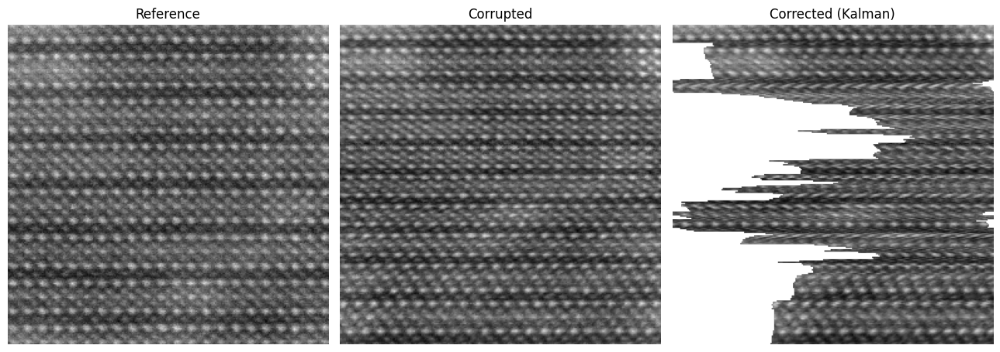

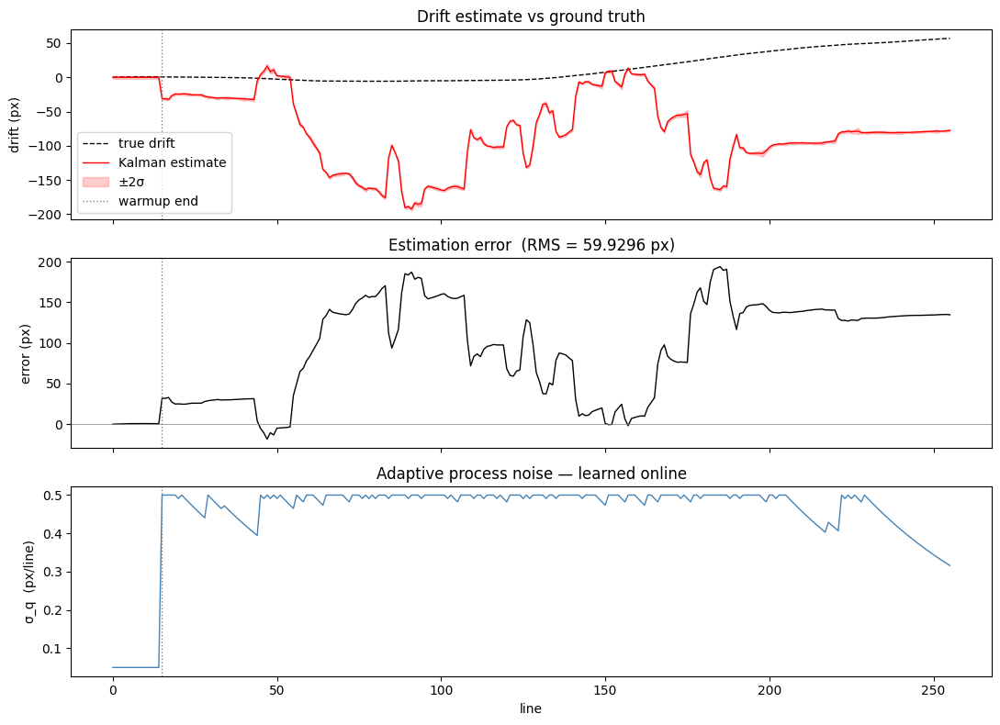

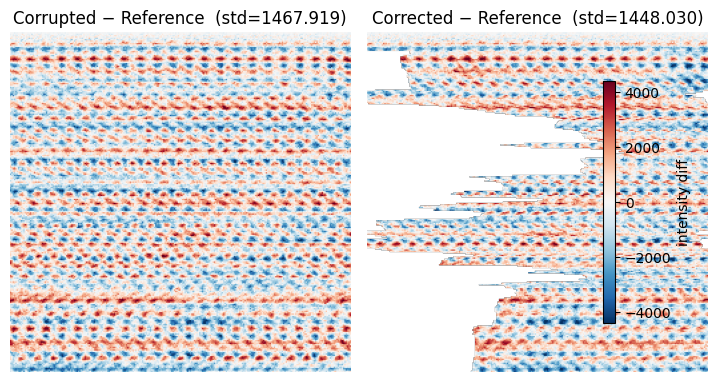

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates


# ── 1. SHIFT ESTIMATOR ────────────────────────────────────────────────────────

def estimate_shift(line_prev, line_curr, max_shift=None):
    """
    Phase correlation + Gaussian peak fit.

    Returns
    -------
    shift      : float — estimated shift in pixels
    shift_std  : float — Gaussian sigma of the peak, used as sqrt(R)
    confidence : float — peak / noise floor ratio
    """
    n = len(line_prev)
    if max_shift is None:
        max_shift = n // 4

    def _norm(x):
        x = x - x.mean()
        s = x.std()
        return x / s if s > 1e-10 else x

    a, b = _norm(line_prev), _norm(line_curr)

    Fa, Fb = np.fft.rfft(a), np.fft.rfft(b)
    cross  = Fa * np.conj(Fb)
    denom  = np.abs(cross)
    pc     = np.fft.irfft(np.where(denom > 1e-10, cross / denom, 0.0), n=n)
    pc     = np.fft.fftshift(pc)
    lags   = np.arange(n) - n // 2

    mask        = np.abs(lags) <= max_shift
    peak_idx    = int(np.argmax(np.where(mask, pc, -np.inf)))
    noise_floor = np.median(np.abs(pc[mask]))
    confidence  = float(pc[peak_idx] / (noise_floor + 1e-10))

    half_w    = 6
    lo, hi    = max(peak_idx - half_w, 0), min(peak_idx + half_w + 1, n)
    fit_lags  = lags[lo:hi].astype(float)
    fit_vals  = pc[lo:hi]
    shift_int = float(lags[peak_idx])
    shift_std = float(max_shift)

    try:
        def gaussian(x, center, sigma, amp, offset):
            return amp * np.exp(-0.5 * ((x - center) / sigma) ** 2) + offset

        popt, pcov = curve_fit(
            gaussian, fit_lags, fit_vals,
            p0=[shift_int, 2.0, float(pc[peak_idx]), float(noise_floor)],
            bounds=([shift_int - half_w, 0.3,  0.0, -np.inf],
                    [shift_int + half_w, half_w, np.inf, np.inf]),
            maxfev=400,
        )
        if np.sqrt(pcov[0, 0]) <= half_w:
            shift_int = float(popt[0])
            shift_std = float(popt[1])
    except (RuntimeError, ValueError):
        pass

    return shift_int, shift_std, confidence


# ── 2. PRIOR ESTIMATION FROM WARMUP LINES ────────────────────────────────────

def estimate_priors(warmup_lines, verbose=True):
    """
    Analyse the first k scan lines to estimate Kalman initial conditions.

    From k lines we get k-1 shift estimates. We extract:
      v0       — mean velocity (px/line)
      sigma_q  — std of velocity increments (process noise)
      R_median — median observation noise variance
      P0       — initial state covariance

    Parameters
    ----------
    warmup_lines : list of 1D arrays, the first k raw scan lines

    Returns
    -------
    x0      : (2,) initial state [d0, v0]
    P0      : (2,2) initial covariance
    sigma_q : float initial process noise
    R_median: float median R across warmup measurements
    """
    shifts, stds = [], []

    for i in range(1, len(warmup_lines)):
        s, std, _ = estimate_shift(warmup_lines[i - 1], warmup_lines[i])
        shifts.append(s)
        stds.append(std)

    shifts = np.array(shifts)
    stds   = np.array(stds)

    # velocity = mean shift per line
    v0 = float(np.mean(shifts))

    # cumulative drift at end of warmup
    d0 = float(np.sum(shifts))

    # sigma_q from variance of velocity changes (acceleration noise)
    velocity_increments = np.diff(shifts)   # how much velocity changed each step
    sigma_q = float(np.std(velocity_increments)) if len(velocity_increments) > 1 else 0.05
    sigma_q = float(np.clip(sigma_q, 0.005, 0.5))

    # R from median fit uncertainty
    R_median = float(np.median(stds ** 2))

    # Initial covariance: uncertainty in d0 scales with accumulated R,
    # uncertainty in v0 scales with spread of shift estimates
    P0 = np.array([
        [float(np.var(np.cumsum(shifts))),  0.0],
        [0.0,                               float(np.var(shifts))],
    ])
    P0 = np.maximum(P0, np.eye(2) * 1e-4)   # ensure positive definite

    x0 = np.array([d0, v0])

    if verbose:
        print(f"Warmup ({len(warmup_lines)} lines):")
        print(f"  initial velocity  v0      = {v0:.4f} px/line")
        print(f"  cumulative drift  d0      = {d0:.4f} px")
        print(f"  process noise     sigma_q = {sigma_q:.4f} px/line")
        print(f"  median obs noise  R       = {R_median:.4f} px²")

    return x0, P0, sigma_q, R_median


# ── 3. KALMAN FORWARD PASS ────────────────────────────────────────────────────

def build_Q(sigma_q):
    return np.array([[sigma_q**2 / 4,  sigma_q**2 / 2],
                     [sigma_q**2 / 2,  sigma_q**2]])


def kalman_forward(stream, n_lines,
                   n_warmup=15,
                   alpha_up=0.3,
                   alpha_down=0.02,
                   sigma_q_min=0.005,
                   sigma_q_max=0.5):
    """
    Forward Kalman filter with warmup-based prior estimation
    and adaptive process noise.

    First n_warmup lines are collected without correction to estimate
    initial velocity, sigma_q, and state covariance from real data.
    Kalman filter then starts with those informed beliefs.
    """
    F = np.array([[1., 1.], [0., 1.]])
    H = np.array([[1., 0.]])

    d_hat        = np.zeros(n_lines)
    x_hist       = np.zeros((n_lines, 2))
    P_hist       = np.zeros((n_lines, 2, 2))
    sigma_q_hist = np.zeros(n_lines)
    true_ux      = np.full(n_lines, np.nan)
    raw_lines    = []

    warmup_buffer = []
    x = np.array([0., 0.])
    P = np.eye(2)

    sigma_q          = 0.05    # placeholder until warmup finishes
    cumulative_shift = 0.0
    prev_line        = None
    x_prev           = x.copy()
    kalman_started   = False

    for frame in stream:
        n    = frame['line_index']
        line = frame['line']
        raw_lines.append(line.copy())

        if 'ux_true' in frame:
            true_ux[n] = frame['ux_true']

        # ── warmup phase: collect lines, no correction ──
        if n < n_warmup:
            warmup_buffer.append(line.copy())
            d_hat[n]        = 0.0
            x_hist[n]       = x
            P_hist[n]       = P
            sigma_q_hist[n] = sigma_q

            # on the last warmup line: estimate priors
            if n == n_warmup - 1:
                x0, P0, sigma_q, R_median = estimate_priors(warmup_buffer)
                x = x0.copy()
                P = P0.copy()
                cumulative_shift = float(x0[0])   # start from estimated d0
                prev_line        = warmup_buffer[-1]
                kalman_started   = True
                print(f"  Kalman filter starting at line {n_warmup}")
            continue

        # ── Kalman phase ──
        shift, shift_std, _ = estimate_shift(prev_line, line)
        cumulative_shift   += shift
        R = shift_std ** 2

        # adaptive sigma_q
        dv = abs(float(x[1]) - float(x_prev[1]))
        if dv > sigma_q:
            sigma_q = alpha_up   * dv     + (1 - alpha_up)   * sigma_q
        else:
            sigma_q = alpha_down * 0.05   + (1 - alpha_down) * sigma_q
        sigma_q = float(np.clip(sigma_q, sigma_q_min, sigma_q_max))

        Q = build_Q(sigma_q)

        # predict
        x_pred = F @ x
        P_pred = F @ P @ F.T + Q

        # update
        z = np.array([cumulative_shift])
        y = z - H @ x_pred
        S = H @ P_pred @ H.T + R
        K = (P_pred @ H.T).flatten() / float(S[0, 0])

        x_prev = x.copy()
        x      = x_pred + K * float(y[0])
        P      = (np.eye(2) - np.outer(K, H)) @ P_pred

        d_hat[n]        = float(x[0])
        x_hist[n]       = x
        P_hist[n]       = P
        sigma_q_hist[n] = sigma_q
        prev_line       = line

    return d_hat, x_hist, P_hist, sigma_q_hist, true_ux, raw_lines


# ── 4. CORRECTION ─────────────────────────────────────────────────────────────

def apply_correction(raw_lines, drift_x):
    H   = len(raw_lines)
    W   = len(raw_lines[0])
    img = np.array(raw_lines, dtype=float)
    corrected = np.full((H, W), np.nan)
    cols = np.arange(W, dtype=float)

    for n in range(H):
        shifted_cols = cols + drift_x[n]
        valid  = (shifted_cols >= 0) & (shifted_cols <= W - 1)
        coords = np.array([np.full(W, float(n)), shifted_cols])
        row    = map_coordinates(img, coords, order=1, mode='constant', cval=np.nan)
        row[~valid] = np.nan
        corrected[n] = row

    return corrected


# ── 5. RUN ────────────────────────────────────────────────────────────────────

stream = corrupted_image_scan_stream(img_cor, true_ux=ux, true_uy=uy)

d_hat, x_hist, P_hist, sigma_q_hist, true_ux_arr, raw_lines = kalman_forward(
    stream, n_lines=len(img_cor),
    n_warmup=15,
    alpha_up=0.3,
    alpha_down=0.02,
    sigma_q_min=0.005,
    sigma_q_max=0.5,
)

img_corrected = apply_correction(raw_lines, d_hat)


# ── 6. VISUALISATION ──────────────────────────────────────────────────────────

lines = np.arange(len(img_cor))
sigma = np.sqrt(P_hist[:, 0, 0])

# images
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
axes[0].imshow(img_ref,       cmap='gray'); axes[0].set_title('Reference');          axes[0].axis('off')
axes[1].imshow(img_cor,       cmap='gray'); axes[1].set_title('Corrupted');          axes[1].axis('off')
axes[2].imshow(img_corrected, cmap='gray'); axes[2].set_title('Corrected (Kalman)'); axes[2].axis('off')
plt.tight_layout(); plt.show()

# drift + error + adaptive sigma_q
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

axes[0].plot(lines, true_ux_arr, 'k--', lw=1, label='true drift')
axes[0].plot(lines, d_hat,       'r',   lw=1, label='Kalman estimate')
axes[0].fill_between(lines, d_hat - 2*sigma, d_hat + 2*sigma,
                     alpha=0.2, color='r', label='±2σ')
axes[0].axvline(15, color='gray', lw=1, ls=':', label='warmup end')
axes[0].set_ylabel('drift (px)'); axes[0].legend()
axes[0].set_title('Drift estimate vs ground truth')

axes[1].plot(lines, true_ux_arr - d_hat, 'k', lw=1)
axes[1].axhline(0, color='gray', lw=0.5)
axes[1].axvline(15, color='gray', lw=1, ls=':')
axes[1].set_ylabel('error (px)')
axes[1].set_title(f'Estimation error  (RMS = {float(np.nanstd(true_ux_arr - d_hat)):.4f} px)')

axes[2].plot(lines, sigma_q_hist, color='steelblue', lw=1)
axes[2].axvline(15, color='gray', lw=1, ls=':')
axes[2].set_ylabel('σ_q  (px/line)'); axes[2].set_xlabel('line')
axes[2].set_title('Adaptive process noise — learned online')

plt.tight_layout(); plt.show()

# difference images
diff_before = img_cor - img_ref
diff_after  = np.where(np.isnan(img_corrected), np.nan, img_corrected - img_ref)
vmax = float(np.nanstd(diff_before)) * 3

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(diff_before, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
axes[0].set_title(f'Corrupted − Reference  (std={float(np.nanstd(diff_before)):.3f})')
axes[0].axis('off')
im = axes[1].imshow(diff_after, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
axes[1].set_title(f'Corrected − Reference  (std={float(np.nanstd(diff_after)):.3f})')
axes[1].axis('off')
plt.colorbar(im, ax=axes.tolist(), shrink=0.7, label='intensity diff')
plt.subplots_adjust(wspace=0.05); plt.show()

Warmup prior estimation (15 lines, max_lag=5):
  measurements used : 60
  initial velocity  : v0      = 4.53702 px/line
  cumulative drift  : d0      = 63.5182 px
  process noise     : sigma_q = 0.50000 px/line
  median obs noise  : R       = 2.3098 px²
  std(d0) = 0.4924 px,  std(v0) = 0.03517 px/line
  Kalman filter starting at line 15



/tmp/ipykernel_21367/2607164161.py:24: RuntimeWarning: invalid value encountered in divide
  pc     = np.fft.irfft(np.where(denom > 1e-10, cross / denom, 0.0), n=n)


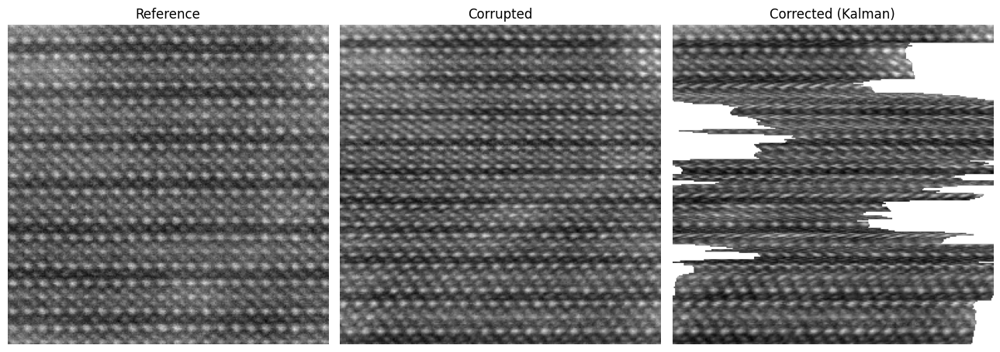

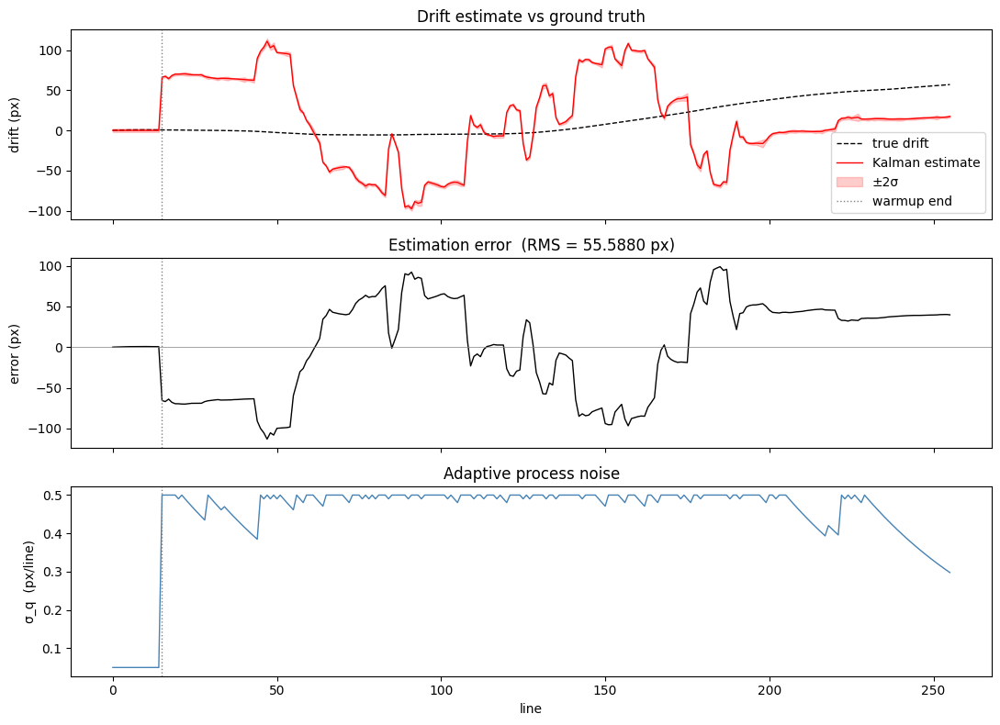

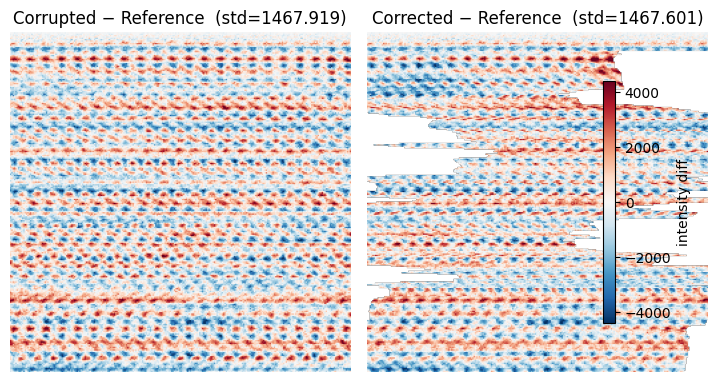

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates


# ── 1. SHIFT ESTIMATOR ────────────────────────────────────────────────────────

def estimate_shift(line_prev, line_curr, max_shift=None):
    n = len(line_prev)
    if max_shift is None:
        max_shift = n // 4

    def _norm(x):
        x = x - x.mean()
        s = x.std()
        return x / s if s > 1e-10 else x

    a, b = _norm(line_prev), _norm(line_curr)

    Fa, Fb = np.fft.rfft(a), np.fft.rfft(b)
    cross  = Fa * np.conj(Fb)
    denom  = np.abs(cross)
    pc     = np.fft.irfft(np.where(denom > 1e-10, cross / denom, 0.0), n=n)
    pc     = np.fft.fftshift(pc)
    lags   = np.arange(n) - n // 2

    mask        = np.abs(lags) <= max_shift
    peak_idx    = int(np.argmax(np.where(mask, pc, -np.inf)))
    noise_floor = np.median(np.abs(pc[mask]))
    confidence  = float(pc[peak_idx] / (noise_floor + 1e-10))

    half_w    = 6
    lo, hi    = max(peak_idx - half_w, 0), min(peak_idx + half_w + 1, n)
    fit_lags  = lags[lo:hi].astype(float)
    fit_vals  = pc[lo:hi]
    shift_int = float(lags[peak_idx])
    shift_std = float(max_shift)

    try:
        def gaussian(x, center, sigma, amp, offset):
            return amp * np.exp(-0.5 * ((x - center) / sigma) ** 2) + offset

        popt, pcov = curve_fit(
            gaussian, fit_lags, fit_vals,
            p0=[shift_int, 2.0, float(pc[peak_idx]), float(noise_floor)],
            bounds=([shift_int - half_w, 0.3,  0.0, -np.inf],
                    [shift_int + half_w, half_w, np.inf, np.inf]),
            maxfev=400,
        )
        if np.sqrt(pcov[0, 0]) <= half_w:
            shift_int = float(popt[0])
            shift_std = float(popt[1])
    except (RuntimeError, ValueError):
        pass

    return shift_int, shift_std, confidence


# ── 2. PRIOR ESTIMATION FROM WARMUP LINES ────────────────────────────────────

def estimate_priors(warmup_lines, max_lag=None, verbose=True):
    n_warmup = len(warmup_lines)
    if max_lag is None:
        max_lag = max(2, n_warmup // 3)

    lags_all, shifts_all, stds_all = [], [], []

    for k in range(1, max_lag + 1):
        for i in range(n_warmup - k):
            s, std, _ = estimate_shift(warmup_lines[i], warmup_lines[i + k])
            lags_all.append(k)
            shifts_all.append(s)
            stds_all.append(std)

    lags_all   = np.array(lags_all,   dtype=float)
    shifts_all = np.array(shifts_all, dtype=float)
    stds_all   = np.array(stds_all,   dtype=float)

    weights = 1.0 / np.maximum(stds_all ** 2, 1e-6)

    # WLS: shift = v * lag  (through origin)
    v0 = float(
        np.sum(weights * lags_all * shifts_all) /
        np.sum(weights * lags_all ** 2)
    )

    residuals            = shifts_all - v0 * lags_all
    normalised_residuals = residuals / np.sqrt(lags_all)
    sigma_q = float(np.clip(np.std(normalised_residuals), 0.005, 0.5))

    d0       = v0 * (n_warmup - 1)
    R_median = float(np.median(stds_all[lags_all == 1] ** 2))

    var_v0 = float(1.0 / np.sum(weights * lags_all ** 2))
    var_d0 = var_v0 * (n_warmup - 1) ** 2
    P0     = np.array([[var_d0, 0.0], [0.0, var_v0]])
    x0     = np.array([d0, v0])

    if verbose:
        print(f"Warmup prior estimation ({n_warmup} lines, max_lag={max_lag}):")
        print(f"  measurements used : {len(shifts_all)}")
        print(f"  initial velocity  : v0      = {v0:.5f} px/line")
        print(f"  cumulative drift  : d0      = {d0:.4f} px")
        print(f"  process noise     : sigma_q = {sigma_q:.5f} px/line")
        print(f"  median obs noise  : R       = {R_median:.4f} px²")
        print(f"  std(d0) = {np.sqrt(var_d0):.4f} px,  std(v0) = {np.sqrt(var_v0):.5f} px/line")

    return x0, P0, sigma_q, R_median


# ── 3. KALMAN FORWARD PASS ────────────────────────────────────────────────────

def build_Q(sigma_q):
    return np.array([[sigma_q**2 / 4,  sigma_q**2 / 2],
                     [sigma_q**2 / 2,  sigma_q**2]])


def kalman_forward(stream, n_lines,
                   n_warmup=15,
                   max_lag=None,
                   alpha_up=0.3,
                   alpha_down=0.02,
                   sigma_q_min=0.005,
                   sigma_q_max=0.5):

    F = np.array([[1., 1.], [0., 1.]])
    H = np.array([[1., 0.]])

    d_hat        = np.zeros(n_lines)
    x_hist       = np.zeros((n_lines, 2))
    P_hist       = np.zeros((n_lines, 2, 2))
    sigma_q_hist = np.zeros(n_lines)
    true_ux      = np.full(n_lines, np.nan)
    raw_lines    = []

    warmup_buffer    = []
    x                = np.array([0., 0.])
    P                = np.eye(2)
    sigma_q          = 0.05
    cumulative_shift = 0.0
    prev_line        = None
    x_prev           = x.copy()

    for frame in stream:
        n    = frame['line_index']
        line = frame['line']
        raw_lines.append(line.copy())

        if 'ux_true' in frame:
            true_ux[n] = frame['ux_true']

        # ── warmup: collect, no correction ──
        if n < n_warmup:
            warmup_buffer.append(line.copy())
            d_hat[n]        = 0.0
            x_hist[n]       = x
            P_hist[n]       = P
            sigma_q_hist[n] = sigma_q

            if n == n_warmup - 1:
                x0, P0, sigma_q, R_median = estimate_priors(
                    warmup_buffer, max_lag=max_lag
                )
                x                = x0.copy()
                P                = P0.copy()
                cumulative_shift = float(x0[0])
                prev_line        = warmup_buffer[-1]
                print(f"  Kalman filter starting at line {n_warmup}\n")
            continue

        # ── Kalman phase ──
        shift, shift_std, _ = estimate_shift(prev_line, line)
        cumulative_shift   += shift
        R = shift_std ** 2

        # adaptive sigma_q
        dv = abs(float(x[1]) - float(x_prev[1]))
        if dv > sigma_q:
            sigma_q = alpha_up   * dv   + (1 - alpha_up)   * sigma_q
        else:
            sigma_q = alpha_down * float(sigma_q_min) + (1 - alpha_down) * sigma_q
        sigma_q = float(np.clip(sigma_q, sigma_q_min, sigma_q_max))

        Q = build_Q(sigma_q)

        x_pred = F @ x
        P_pred = F @ P @ F.T + Q

        z = np.array([cumulative_shift])
        y = z - H @ x_pred
        S = H @ P_pred @ H.T + R
        K = (P_pred @ H.T).flatten() / float(S[0, 0])

        x_prev = x.copy()
        x      = x_pred + K * float(y[0])
        P      = (np.eye(2) - np.outer(K, H)) @ P_pred

        d_hat[n]        = float(x[0])
        x_hist[n]       = x
        P_hist[n]       = P
        sigma_q_hist[n] = sigma_q
        prev_line       = line

    return d_hat, x_hist, P_hist, sigma_q_hist, true_ux, raw_lines


# ── 4. CORRECTION ─────────────────────────────────────────────────────────────

def apply_correction(raw_lines, drift_x):
    H   = len(raw_lines)
    W   = len(raw_lines[0])
    img = np.array(raw_lines, dtype=float)
    corrected = np.full((H, W), np.nan)
    cols = np.arange(W, dtype=float)

    for n in range(H):
        shifted_cols = cols + drift_x[n]
        valid  = (shifted_cols >= 0) & (shifted_cols <= W - 1)
        coords = np.array([np.full(W, float(n)), shifted_cols])
        row    = map_coordinates(img, coords, order=1, mode='constant', cval=np.nan)
        row[~valid] = np.nan
        corrected[n] = row

    return corrected


# ── 5. RUN ────────────────────────────────────────────────────────────────────

stream = corrupted_image_scan_stream(img_cor, true_ux=ux, true_uy=uy)

d_hat, x_hist, P_hist, sigma_q_hist, true_ux_arr, raw_lines = kalman_forward(
    stream, n_lines=len(img_cor),
    n_warmup=15,
    max_lag=None,       # defaults to n_warmup // 3 = 5
    alpha_up=0.3,
    alpha_down=0.02,
    sigma_q_min=0.005,
    sigma_q_max=0.5,
)

img_corrected = apply_correction(raw_lines, d_hat)


# ── 6. VISUALISATION ──────────────────────────────────────────────────────────

lines = np.arange(len(img_cor))
sigma = np.sqrt(P_hist[:, 0, 0])

# images
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
axes[0].imshow(img_ref,       cmap='gray'); axes[0].set_title('Reference');          axes[0].axis('off')
axes[1].imshow(img_cor,       cmap='gray'); axes[1].set_title('Corrupted');          axes[1].axis('off')
axes[2].imshow(img_corrected, cmap='gray'); axes[2].set_title('Corrected (Kalman)'); axes[2].axis('off')
plt.tight_layout(); plt.show()

# drift + error + sigma_q
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

axes[0].plot(lines, true_ux_arr, 'k--', lw=1, label='true drift')
axes[0].plot(lines, d_hat,       'r',   lw=1, label='Kalman estimate')
axes[0].fill_between(lines, d_hat - 2*sigma, d_hat + 2*sigma,
                     alpha=0.2, color='r', label='±2σ')
axes[0].axvline(15, color='gray', lw=1, ls=':', label='warmup end')
axes[0].set_ylabel('drift (px)'); axes[0].legend()
axes[0].set_title('Drift estimate vs ground truth')

axes[1].plot(lines, true_ux_arr - d_hat, 'k', lw=1)
axes[1].axhline(0, color='gray', lw=0.5)
axes[1].axvline(15, color='gray', lw=1, ls=':')
axes[1].set_ylabel('error (px)')
axes[1].set_title(f'Estimation error  (RMS = {float(np.nanstd(true_ux_arr - d_hat)):.4f} px)')

axes[2].plot(lines, sigma_q_hist, color='steelblue', lw=1)
axes[2].axvline(15, color='gray', lw=1, ls=':')
axes[2].set_ylabel('σ_q  (px/line)'); axes[2].set_xlabel('line')
axes[2].set_title('Adaptive process noise')

plt.tight_layout(); plt.show()

# difference images
diff_before = img_cor - img_ref
diff_after  = np.where(np.isnan(img_corrected), np.nan, img_corrected - img_ref)
vmax = float(np.nanstd(diff_before)) * 3

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(diff_before, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
axes[0].set_title(f'Corrupted − Reference  (std={float(np.nanstd(diff_before)):.3f})')
axes[0].axis('off')
im = axes[1].imshow(diff_after, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
axes[1].set_title(f'Corrected − Reference  (std={float(np.nanstd(diff_after)):.3f})')
axes[1].axis('off')
plt.colorbar(im, ax=axes.tolist(), shrink=0.7, label='intensity diff')
plt.subplots_adjust(wspace=0.05); plt.show()

Warmup prior estimation (15 lines, max_lag=5):
  measurements used : 60
  initial velocity  : v0      = -0.41238 px/line
  cumulative drift  : d0      = -5.7733 px
  process noise     : sigma_q = 0.50000 px/line
  median obs noise  : R       = 1.7510 px²
  std(d0) = 0.6805 px,  std(v0) = 0.04861 px/line
  Kalman filter starting at line 15



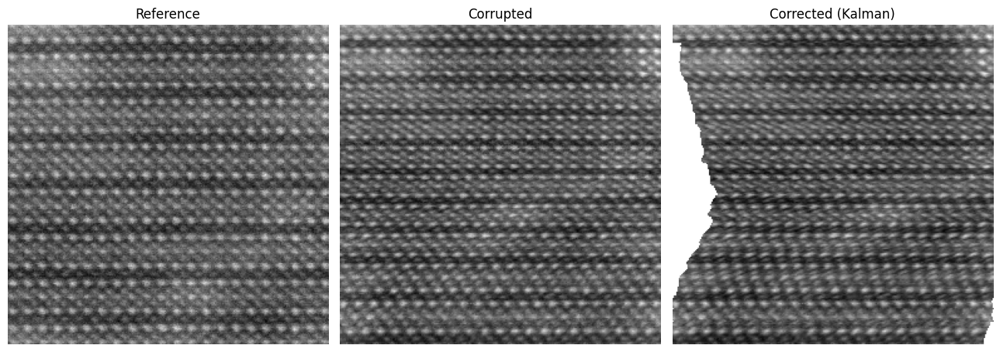

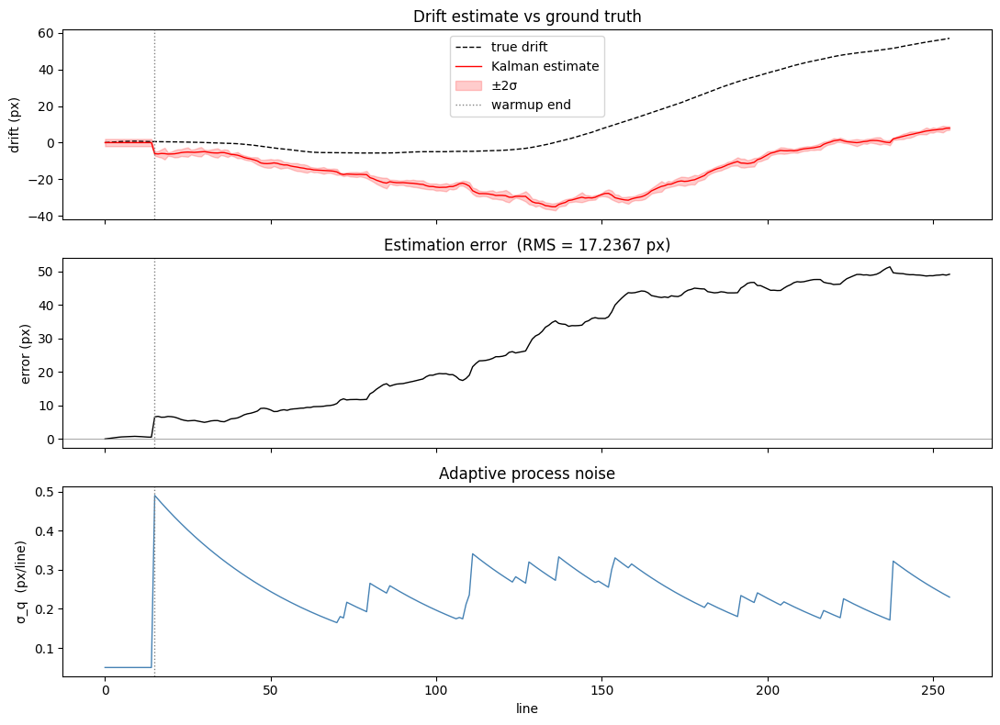

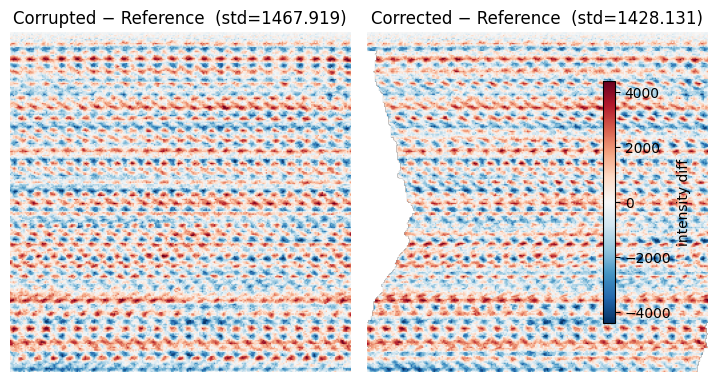

In [38]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates


# ── 1. SHIFT ESTIMATOR ────────────────────────────────────────────────────────

def estimate_shift(line_prev, line_curr,
                   search_center=0.0,
                   search_half=5.0):
    """
    Phase correlation + Gaussian peak fit with:
      - Hann apodization  (kills edge/periodicity artefacts)
      - constrained search window around predicted shift

    Parameters
    ----------
    line_prev, line_curr : 1D arrays
    search_center : float — expected shift (px), from Kalman velocity prediction
    search_half   : float — half-width of search window around search_center (px)

    Returns
    -------
    shift      : float — estimated shift in pixels
    shift_std  : float — Gaussian sigma, used as sqrt(R)
    confidence : float — peak / noise floor
    """
    n = len(line_prev)

    def _norm(x):
        x = x - x.mean()
        s = x.std()
        return x / s if s > 1e-10 else x

    # apodization: taper edges to zero to kill boundary/periodicity artefacts
    window = np.hanning(n)
    a = _norm(line_prev) * window
    b = _norm(line_curr) * window

    Fa, Fb = np.fft.rfft(a), np.fft.rfft(b)
    cross  = Fa * np.conj(Fb)
    denom  = np.abs(cross)
    pc     = np.fft.irfft(np.where(denom > 1e-10, cross / denom, 0.0), n=n)
    pc     = np.fft.fftshift(pc)
    lags   = np.arange(n) - n // 2

    # constrained search: only look near the predicted shift
    lo = search_center - search_half
    hi = search_center + search_half
    mask     = (lags >= lo) & (lags <= hi)
    if mask.sum() < 3:
        # fallback: open up to full ±n//4 if window too narrow
        mask = np.abs(lags) <= n // 4

    peak_idx    = int(np.argmax(np.where(mask, pc, -np.inf)))
    noise_floor = np.median(np.abs(pc[mask]))
    confidence  = float(pc[peak_idx] / (noise_floor + 1e-10))

    half_w    = 6
    lo_f, hi_f = max(peak_idx - half_w, 0), min(peak_idx + half_w + 1, n)
    fit_lags  = lags[lo_f:hi_f].astype(float)
    fit_vals  = pc[lo_f:hi_f]
    shift_int = float(lags[peak_idx])
    shift_std = float(search_half)   # fallback uncertainty

    try:
        def gaussian(x, center, sigma, amp, offset):
            return amp * np.exp(-0.5 * ((x - center) / sigma) ** 2) + offset

        popt, pcov = curve_fit(
            gaussian, fit_lags, fit_vals,
            p0=[shift_int, 2.0, float(pc[peak_idx]), float(noise_floor)],
            bounds=([shift_int - half_w, 0.3,  0.0, -np.inf],
                    [shift_int + half_w, half_w, np.inf, np.inf]),
            maxfev=400,
        )
        if np.sqrt(pcov[0, 0]) <= half_w:
            shift_int = float(popt[0])
            shift_std = float(popt[1])
    except (RuntimeError, ValueError):
        pass

    return shift_int, shift_std, confidence


# ── 2. PRIOR ESTIMATION FROM WARMUP LINES ────────────────────────────────────

def estimate_priors(warmup_lines, max_lag=None, verbose=True):
    n_warmup = len(warmup_lines)
    if max_lag is None:
        max_lag = max(2, n_warmup // 3)

    lags_all, shifts_all, stds_all = [], [], []

    for k in range(1, max_lag + 1):
        # search window for warmup: lag-scaled, no prior velocity yet
        search_half = min(k * 3.0, 15.0)
        for i in range(n_warmup - k):
            s, std, _ = estimate_shift(
                warmup_lines[i], warmup_lines[i + k],
                search_center=0.0,
                search_half=search_half,
            )
            lags_all.append(k)
            shifts_all.append(s)
            stds_all.append(std)

    lags_all   = np.array(lags_all,   dtype=float)
    shifts_all = np.array(shifts_all, dtype=float)
    stds_all   = np.array(stds_all,   dtype=float)

    weights = 1.0 / np.maximum(stds_all ** 2, 1e-6)

    v0 = float(
        np.sum(weights * lags_all * shifts_all) /
        np.sum(weights * lags_all ** 2)
    )

    residuals            = shifts_all - v0 * lags_all
    normalised_residuals = residuals / np.sqrt(lags_all)
    sigma_q = float(np.clip(np.std(normalised_residuals), 0.005, 0.5))

    d0       = v0 * (n_warmup - 1)
    R_median = float(np.median(stds_all[lags_all == 1] ** 2))

    var_v0 = float(1.0 / np.sum(weights * lags_all ** 2))
    var_d0 = var_v0 * (n_warmup - 1) ** 2
    P0     = np.array([[var_d0, 0.0], [0.0, var_v0]])
    x0     = np.array([d0, v0])

    if verbose:
        print(f"Warmup prior estimation ({n_warmup} lines, max_lag={max_lag}):")
        print(f"  measurements used : {len(shifts_all)}")
        print(f"  initial velocity  : v0      = {v0:.5f} px/line")
        print(f"  cumulative drift  : d0      = {d0:.4f} px")
        print(f"  process noise     : sigma_q = {sigma_q:.5f} px/line")
        print(f"  median obs noise  : R       = {R_median:.4f} px²")
        print(f"  std(d0) = {np.sqrt(var_d0):.4f} px,  "
              f"std(v0) = {np.sqrt(var_v0):.5f} px/line")

    return x0, P0, sigma_q, R_median


# ── 3. KALMAN FORWARD PASS ────────────────────────────────────────────────────

def build_Q(sigma_q):
    return np.array([[sigma_q**2 / 4,  sigma_q**2 / 2],
                     [sigma_q**2 / 2,  sigma_q**2]])


def kalman_forward(stream, n_lines,
                   n_warmup=15,
                   max_lag=None,
                   alpha_up=0.3,
                   alpha_down=0.02,
                   sigma_q_min=0.005,
                   sigma_q_max=0.5,
                   search_half_init=5.0,
                   search_half_min=2.0):
    """
    Forward Kalman filter.
    After warmup the predicted velocity x_pred[1] is passed to
    estimate_shift as search_center, so the CC only looks near
    where the filter expects the shift to be.
    search_half shrinks as the filter gains confidence (2*sigma_v).
    """
    F = np.array([[1., 1.], [0., 1.]])
    H = np.array([[1., 0.]])

    d_hat        = np.zeros(n_lines)
    x_hist       = np.zeros((n_lines, 2))
    P_hist       = np.zeros((n_lines, 2, 2))
    sigma_q_hist = np.zeros(n_lines)
    true_ux      = np.full(n_lines, np.nan)
    raw_lines    = []

    warmup_buffer    = []
    x                = np.array([0., 0.])
    P                = np.eye(2)
    sigma_q          = 0.05
    cumulative_shift = 0.0
    prev_line        = None
    x_prev           = x.copy()

    for frame in stream:
        n    = frame['line_index']
        line = frame['line']
        raw_lines.append(line.copy())

        if 'ux_true' in frame:
            true_ux[n] = frame['ux_true']

        # ── warmup phase ──
        if n < n_warmup:
            warmup_buffer.append(line.copy())
            d_hat[n]        = 0.0
            x_hist[n]       = x
            P_hist[n]       = P
            sigma_q_hist[n] = sigma_q

            if n == n_warmup - 1:
                x0, P0, sigma_q, R_median = estimate_priors(
                    warmup_buffer, max_lag=max_lag
                )
                x                = x0.copy()
                P                = P0.copy()
                cumulative_shift = float(x0[0])
                prev_line        = warmup_buffer[-1]
                print(f"  Kalman filter starting at line {n_warmup}\n")
            continue

        # ── Kalman predict first — use prediction to constrain CC ──
        Q      = build_Q(sigma_q)
        x_pred = F @ x
        P_pred = F @ P @ F.T + Q

        # search window: center on predicted velocity, width = 2*sigma_v
        search_center = float(x_pred[1])
        search_half   = max(search_half_min,
                            2.0 * float(np.sqrt(P_pred[1, 1])))
        search_half   = min(search_half, search_half_init)

        # ── measure ──
        shift, shift_std, _ = estimate_shift(
            prev_line, line,
            search_center=search_center,
            search_half=search_half,
        )
        cumulative_shift += shift
        R = shift_std ** 2

        # ── Kalman update ──
        z = np.array([cumulative_shift])
        y = z - H @ x_pred
        S = H @ P_pred @ H.T + R
        K = (P_pred @ H.T).flatten() / float(S[0, 0])

        x_prev = x.copy()
        x      = x_pred + K * float(y[0])
        P      = (np.eye(2) - np.outer(K, H)) @ P_pred

        # ── adaptive sigma_q ──
        dv = abs(float(x[1]) - float(x_prev[1]))
        if dv > sigma_q:
            sigma_q = alpha_up   * dv             + (1 - alpha_up)   * sigma_q
        else:
            sigma_q = alpha_down * sigma_q_min    + (1 - alpha_down) * sigma_q
        sigma_q = float(np.clip(sigma_q, sigma_q_min, sigma_q_max))

        d_hat[n]        = float(x[0])
        x_hist[n]       = x
        P_hist[n]       = P
        sigma_q_hist[n] = sigma_q
        prev_line       = line

    return d_hat, x_hist, P_hist, sigma_q_hist, true_ux, raw_lines


# ── 4. CORRECTION ─────────────────────────────────────────────────────────────

def apply_correction(raw_lines, drift_x):
    H   = len(raw_lines)
    W   = len(raw_lines[0])
    img = np.array(raw_lines, dtype=float)
    corrected = np.full((H, W), np.nan)
    cols = np.arange(W, dtype=float)

    for n in range(H):
        shifted_cols = cols + drift_x[n]
        valid  = (shifted_cols >= 0) & (shifted_cols <= W - 1)
        coords = np.array([np.full(W, float(n)), shifted_cols])
        row    = map_coordinates(img, coords, order=1, mode='constant', cval=np.nan)
        row[~valid] = np.nan
        corrected[n] = row

    return corrected


# ── 5. RUN ────────────────────────────────────────────────────────────────────

stream = corrupted_image_scan_stream(img_cor, true_ux=ux, true_uy=uy)

d_hat, x_hist, P_hist, sigma_q_hist, true_ux_arr, raw_lines = kalman_forward(
    stream, n_lines=len(img_cor),
    n_warmup=15,
    max_lag=None,
    alpha_up=0.3,
    alpha_down=0.02,
    sigma_q_min=0.005,
    sigma_q_max=0.5,
    search_half_init=5.0,
    search_half_min=2.0,
)

img_corrected = apply_correction(raw_lines, d_hat)


# ── 6. VISUALISATION ──────────────────────────────────────────────────────────

lines = np.arange(len(img_cor))
sigma = np.sqrt(P_hist[:, 0, 0])

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
axes[0].imshow(img_ref,       cmap='gray'); axes[0].set_title('Reference');          axes[0].axis('off')
axes[1].imshow(img_cor,       cmap='gray'); axes[1].set_title('Corrupted');          axes[1].axis('off')
axes[2].imshow(img_corrected, cmap='gray'); axes[2].set_title('Corrected (Kalman)'); axes[2].axis('off')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

axes[0].plot(lines, true_ux_arr, 'k--', lw=1, label='true drift')
axes[0].plot(lines, d_hat,       'r',   lw=1, label='Kalman estimate')
axes[0].fill_between(lines, d_hat - 2*sigma, d_hat + 2*sigma,
                     alpha=0.2, color='r', label='±2σ')
axes[0].axvline(15, color='gray', lw=1, ls=':', label='warmup end')
axes[0].set_ylabel('drift (px)'); axes[0].legend()
axes[0].set_title('Drift estimate vs ground truth')

axes[1].plot(lines, true_ux_arr - d_hat, 'k', lw=1)
axes[1].axhline(0, color='gray', lw=0.5)
axes[1].axvline(15, color='gray', lw=1, ls=':')
axes[1].set_ylabel('error (px)')
axes[1].set_title(f'Estimation error  (RMS = {float(np.nanstd(true_ux_arr - d_hat)):.4f} px)')

axes[2].plot(lines, sigma_q_hist, color='steelblue', lw=1)
axes[2].axvline(15, color='gray', lw=1, ls=':')
axes[2].set_ylabel('σ_q  (px/line)'); axes[2].set_xlabel('line')
axes[2].set_title('Adaptive process noise')

plt.tight_layout(); plt.show()

diff_before = img_cor - img_ref
diff_after  = np.where(np.isnan(img_corrected), np.nan, img_corrected - img_ref)
vmax = float(np.nanstd(diff_before)) * 3

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(diff_before, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
axes[0].set_title(f'Corrupted − Reference  (std={float(np.nanstd(diff_before)):.3f})')
axes[0].axis('off')
im = axes[1].imshow(diff_after, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
axes[1].set_title(f'Corrected − Reference  (std={float(np.nanstd(diff_after)):.3f})')
axes[1].axis('off')
plt.colorbar(im, ax=axes.tolist(), shrink=0.7, label='intensity diff')
plt.subplots_adjust(wspace=0.05); plt.show()

Warmup prior estimation (25 lines, max_lag=8):
  measurements used : 164
  initial velocity  : v0      = 0.39887 px/line
  cumulative drift  : d0      = 9.5729 px
  process noise     : sigma_q = 0.50000 px/line
  median obs noise  : R       = 2.1420 px²
  std(d0) = 0.3699 px,  std(v0) = 0.01541 px/line
  Kalman filter starting at line 25



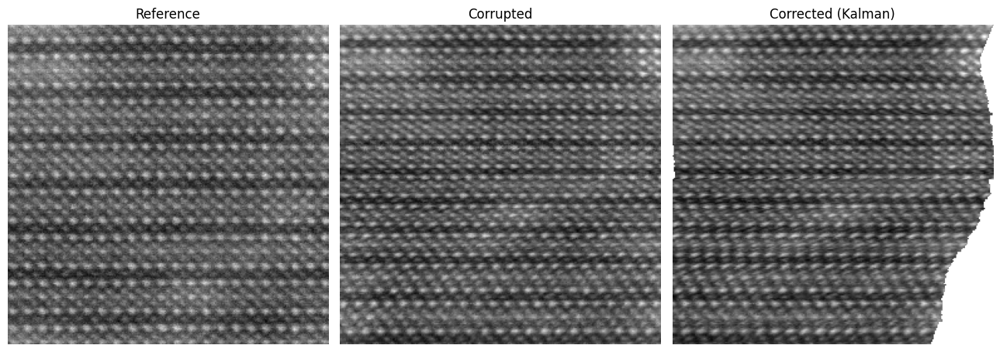

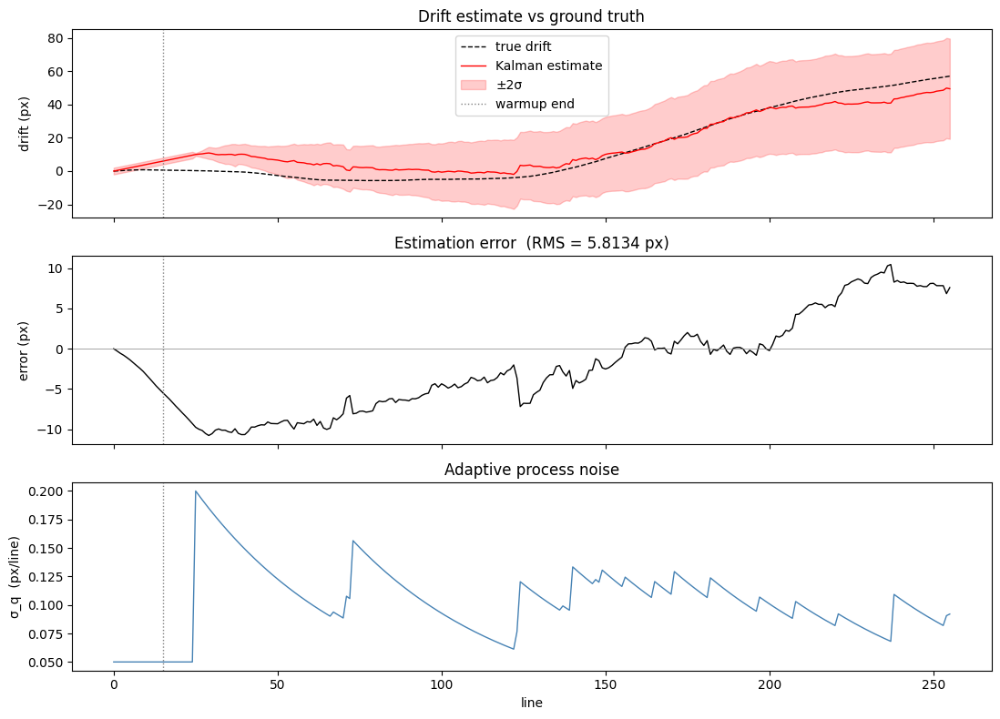

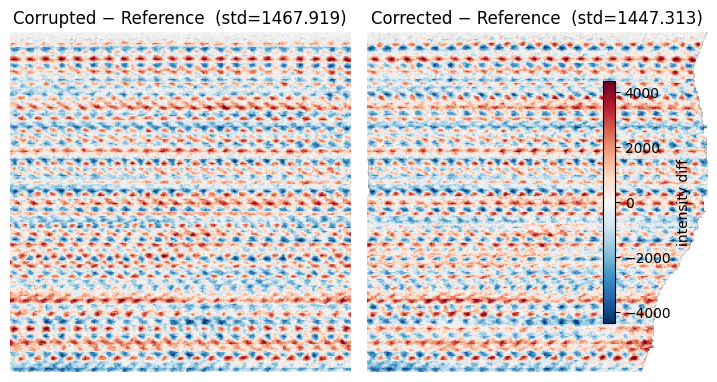

In [41]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates


# ── 1. SHIFT ESTIMATOR ────────────────────────────────────────────────────────

def estimate_shift(line_prev, line_curr,
                   search_center=0.0,
                   search_half=5.0):
    """
    Phase correlation + Gaussian peak fit.
    Hann apodization kills edge/periodicity artefacts.
    Constrained search window prevents lattice-period jumps.
    """
    n = len(line_prev)

    def _norm(x):
        x = x - x.mean()
        s = x.std()
        return x / s if s > 1e-10 else x

    window = np.hanning(n)
    a = _norm(line_prev) * window
    b = _norm(line_curr) * window

    Fa, Fb = np.fft.rfft(a), np.fft.rfft(b)
    cross  = Fa * np.conj(Fb)
    denom  = np.abs(cross)
    pc     = np.fft.irfft(np.where(denom > 1e-10, cross / denom, 0.0), n=n)
    pc     = np.fft.fftshift(pc)
    lags   = np.arange(n) - n // 2

    lo   = search_center - search_half
    hi   = search_center + search_half
    mask = (lags >= lo) & (lags <= hi)
    if mask.sum() < 3:
        mask = np.abs(lags) <= n // 4

    peak_idx    = int(np.argmax(np.where(mask, pc, -np.inf)))
    noise_floor = np.median(np.abs(pc[mask]))
    confidence  = float(pc[peak_idx] / (noise_floor + 1e-10))

    half_w     = 6
    lo_f, hi_f = max(peak_idx - half_w, 0), min(peak_idx + half_w + 1, n)
    fit_lags   = lags[lo_f:hi_f].astype(float)
    fit_vals   = pc[lo_f:hi_f]
    shift_int  = float(lags[peak_idx])
    shift_std  = float(search_half)

    try:
        def gaussian(x, center, sigma, amp, offset):
            return amp * np.exp(-0.5 * ((x - center) / sigma) ** 2) + offset

        popt, pcov = curve_fit(
            gaussian, fit_lags, fit_vals,
            p0=[shift_int, 2.0, float(pc[peak_idx]), float(noise_floor)],
            bounds=([shift_int - half_w, 0.3,  0.0, -np.inf],
                    [shift_int + half_w, half_w, np.inf, np.inf]),
            maxfev=400,
        )
        if np.sqrt(pcov[0, 0]) <= half_w:
            shift_int = float(popt[0])
            shift_std = float(popt[1])
    except (RuntimeError, ValueError):
        pass

    return shift_int, shift_std, confidence


# ── 2. PRIOR ESTIMATION FROM WARMUP LINES ────────────────────────────────────

def estimate_priors(warmup_lines, max_lag=None, verbose=True):
    n_warmup = len(warmup_lines)
    if max_lag is None:
        max_lag = max(2, n_warmup // 3)

    lags_all, shifts_all, stds_all = [], [], []

    for k in range(1, max_lag + 1):
        search_half = min(k * 3.0, 15.0)
        for i in range(n_warmup - k):
            s, std, _ = estimate_shift(
                warmup_lines[i], warmup_lines[i + k],
                search_center=0.0,
                search_half=search_half,
            )
            lags_all.append(k)
            shifts_all.append(s)
            stds_all.append(std)

    lags_all   = np.array(lags_all,   dtype=float)
    shifts_all = np.array(shifts_all, dtype=float)
    stds_all   = np.array(stds_all,   dtype=float)

    weights = 1.0 / np.maximum(stds_all ** 2, 1e-6)

    v0 = float(
        np.sum(weights * lags_all * shifts_all) /
        np.sum(weights * lags_all ** 2)
    )

    residuals            = shifts_all - v0 * lags_all
    normalised_residuals = residuals / np.sqrt(lags_all)
    sigma_q = float(np.clip(np.std(normalised_residuals), 0.005, 0.5))

    d0       = v0 * (n_warmup - 1)
    R_median = float(np.median(stds_all[lags_all == 1] ** 2))

    var_v0 = float(1.0 / np.sum(weights * lags_all ** 2))
    var_d0 = var_v0 * (n_warmup - 1) ** 2
    P0     = np.array([[var_d0, 0.0], [0.0, var_v0]])
    x0     = np.array([d0, v0])

    if verbose:
        print(f"Warmup prior estimation ({n_warmup} lines, max_lag={max_lag}):")
        print(f"  measurements used : {len(shifts_all)}")
        print(f"  initial velocity  : v0      = {v0:.5f} px/line")
        print(f"  cumulative drift  : d0      = {d0:.4f} px")
        print(f"  process noise     : sigma_q = {sigma_q:.5f} px/line")
        print(f"  median obs noise  : R       = {R_median:.4f} px²")
        print(f"  std(d0) = {np.sqrt(var_d0):.4f} px,  "
              f"std(v0) = {np.sqrt(var_v0):.5f} px/line")

    return x0, P0, sigma_q, R_median


# ── 3. KALMAN FORWARD PASS ────────────────────────────────────────────────────

def build_Q(sigma_q):
    return np.array([[sigma_q**2 / 4,  sigma_q**2 / 2],
                     [sigma_q**2 / 2,  sigma_q**2]])


def kalman_forward(stream, n_lines,
                   n_warmup=15,
                   max_lag=None,
                   alpha_up=0.3,
                   alpha_down=0.02,
                   sigma_q_min=0.005,
                   sigma_q_max=0.5,
                   search_half_init=5.0,
                   search_half_min=2.0):
    """
    Forward Kalman filter with incremental observations.

    State:       x = [d, v]
    Transition:  d[n] = d[n-1] + v[n-1]
                 v[n] = v[n-1] + q
    Observation: z = shift(n, n-1) ≈ v[n-1]  →  H = [0, 1]

    Position d accumulates through the state transition itself —
    no explicit cumulative sum, so noise does not pile up over time.
    """
    F = np.array([[1., 1.], [0., 1.]])
    H = np.array([[0., 1.]])          # observe velocity from increment

    d_hat        = np.zeros(n_lines)
    x_hist       = np.zeros((n_lines, 2))
    P_hist       = np.zeros((n_lines, 2, 2))
    sigma_q_hist = np.zeros(n_lines)
    true_ux      = np.full(n_lines, np.nan)
    raw_lines    = []

    warmup_buffer = []
    x             = np.array([0., 0.])
    P             = np.eye(2)
    sigma_q       = 0.05
    prev_line     = None
    x_prev        = x.copy()

    for frame in stream:
        n    = frame['line_index']
        line = frame['line']
        raw_lines.append(line.copy())

        if 'ux_true' in frame:
            true_ux[n] = frame['ux_true']

        # ── warmup phase ──
        if n < n_warmup:
            warmup_buffer.append(line.copy())
            d_hat[n]        = 0.0
            x_hist[n]       = x
            P_hist[n]       = P
            sigma_q_hist[n] = sigma_q

            if n == n_warmup - 1:
                x0, P0, sigma_q, _ = estimate_priors(
                    warmup_buffer, max_lag=max_lag
                )
                x         = x0.copy()
                P         = P0.copy()
                prev_line = warmup_buffer[-1]

                # backfill warmup lines with linear drift from estimated v0
                v0 = float(x0[1])
                for k in range(n_warmup):
                    d_hat[k] = v0 * k

                print(f"  Kalman filter starting at line {n_warmup}\n")
            continue

        # ── predict first — use to constrain CC search ──
        Q      = build_Q(sigma_q)
        x_pred = F @ x
        P_pred = F @ P @ F.T + Q

        # search window centered on predicted velocity
        search_center = float(x_pred[1])
        search_half   = float(np.clip(
            2.0 * np.sqrt(P_pred[1, 1]),
            search_half_min,
            search_half_init,
        ))

        # ── measure increment ──
        shift, shift_std, _ = estimate_shift(
            prev_line, line,
            search_center=search_center,
            search_half=search_half,
        )
        R = shift_std ** 2

        # ── update: z = shift ≈ v ──
        z = np.array([shift])
        y = z - H @ x_pred
        S = H @ P_pred @ H.T + R
        K = (P_pred @ H.T).flatten() / float(S[0, 0])

        x_prev = x.copy()
        x      = x_pred + K * float(y[0])
        P      = (np.eye(2) - np.outer(K, H)) @ P_pred

        # ── adaptive sigma_q ──
        dv = abs(float(x[1]) - float(x_prev[1]))
        if dv > sigma_q:
            sigma_q = alpha_up   * dv          + (1 - alpha_up)   * sigma_q
        else:
            sigma_q = alpha_down * sigma_q_min + (1 - alpha_down) * sigma_q
        sigma_q = float(np.clip(sigma_q, sigma_q_min, sigma_q_max))

        d_hat[n]        = float(x[0])
        x_hist[n]       = x
        P_hist[n]       = P
        sigma_q_hist[n] = sigma_q
        prev_line       = line

    return d_hat, x_hist, P_hist, sigma_q_hist, true_ux, raw_lines


# ── 4. CORRECTION ─────────────────────────────────────────────────────────────

def apply_correction(raw_lines, drift_x):
    H   = len(raw_lines)
    W   = len(raw_lines[0])
    img = np.array(raw_lines, dtype=float)
    corrected = np.full((H, W), np.nan)
    cols = np.arange(W, dtype=float)

    for n in range(H):
        shifted_cols = cols + drift_x[n]
        valid  = (shifted_cols >= 0) & (shifted_cols <= W - 1)
        coords = np.array([np.full(W, float(n)), shifted_cols])
        row    = map_coordinates(img, coords, order=1, mode='constant', cval=np.nan)
        row[~valid] = np.nan
        corrected[n] = row

    return corrected


# ── 5. RUN ────────────────────────────────────────────────────────────────────

stream = corrupted_image_scan_stream(img_cor, true_ux=ux, true_uy=uy)

d_hat, x_hist, P_hist, sigma_q_hist, true_ux_arr, raw_lines = kalman_forward(
    stream, n_lines=len(img_cor),
    n_warmup=25,
    max_lag=None,
    alpha_up=0.3,
    alpha_down=0.02,
    sigma_q_min=0.005,
    sigma_q_max=0.2,
    search_half_init=5.0,
    search_half_min=2.0,
)

img_corrected = apply_correction(raw_lines, d_hat)


# ── 6. VISUALISATION ──────────────────────────────────────────────────────────

lines = np.arange(len(img_cor))
sigma = np.sqrt(P_hist[:, 0, 0])

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
axes[0].imshow(img_ref,       cmap='gray'); axes[0].set_title('Reference');          axes[0].axis('off')
axes[1].imshow(img_cor,       cmap='gray'); axes[1].set_title('Corrupted');          axes[1].axis('off')
axes[2].imshow(img_corrected, cmap='gray'); axes[2].set_title('Corrected (Kalman)'); axes[2].axis('off')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

axes[0].plot(lines, true_ux_arr, 'k--', lw=1, label='true drift')
axes[0].plot(lines, d_hat,       'r',   lw=1, label='Kalman estimate')
axes[0].fill_between(lines, d_hat - 2*sigma, d_hat + 2*sigma,
                     alpha=0.2, color='r', label='±2σ')
axes[0].axvline(n_warmup := 15, color='gray', lw=1, ls=':', label='warmup end')
axes[0].set_ylabel('drift (px)'); axes[0].legend()
axes[0].set_title('Drift estimate vs ground truth')

axes[1].plot(lines, true_ux_arr - d_hat, 'k', lw=1)
axes[1].axhline(0, color='gray', lw=0.5)
axes[1].axvline(15, color='gray', lw=1, ls=':')
axes[1].set_ylabel('error (px)')
axes[1].set_title(f'Estimation error  (RMS = {float(np.nanstd(true_ux_arr - d_hat)):.4f} px)')

axes[2].plot(lines, sigma_q_hist, color='steelblue', lw=1)
axes[2].axvline(15, color='gray', lw=1, ls=':')
axes[2].set_ylabel('σ_q  (px/line)'); axes[2].set_xlabel('line')
axes[2].set_title('Adaptive process noise')

plt.tight_layout(); plt.show()

diff_before = img_cor - img_ref
diff_after  = np.where(np.isnan(img_corrected), np.nan, img_corrected - img_ref)
vmax = float(np.nanstd(diff_before)) * 3

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(diff_before, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
axes[0].set_title(f'Corrupted − Reference  (std={float(np.nanstd(diff_before)):.3f})')
axes[0].axis('off')
im = axes[1].imshow(diff_after, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
axes[1].set_title(f'Corrected − Reference  (std={float(np.nanstd(diff_after)):.3f})')
axes[1].axis('off')
plt.colorbar(im, ax=axes.tolist(), shrink=0.7, label='intensity diff')
plt.subplots_adjust(wspace=0.05); plt.show()

Step 1 — measuring the shift between lines
- Phase correlation — instead of raw overlap, we equalize all frequencies first so sharp atomic peaks don't dominate
- Hann window — we fade the edges of each line to zero before comparing, so the periodic atom pattern doesn't confuse us into picking the wrong peak

Step 2 — warmup: learning before we start correcting

- how fast the sample is drifting (velocity)
- how noisy our shift measurements are
- how much the velocity changes from line to line

Step 3 — Kalman filter: tracking drift line by line

Step 4 — adaptive process noise

Warmup prior estimation (35 lines, max_lag=11):
  pass-1 rough v0   : -0.08006 px/line  (median lag-1)
  measurements used : 319
  initial velocity  : v0      = 0.02788 px/line
  cumulative drift  : d0      = 0.0000 px
  process noise     : sigma_q = 0.50000 px/line
  median obs noise  : R       = 1.4691 px²
  std(d0) = 0.0094 px,  std(v0) = 0.00943 px/line
  Kalman filter starting at line 35



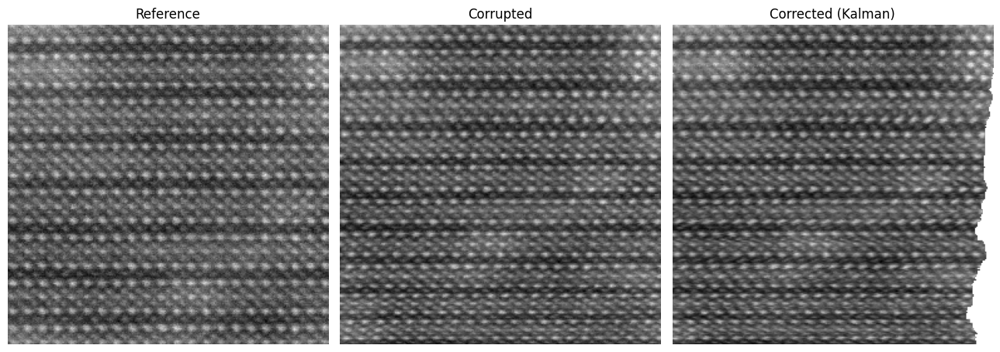

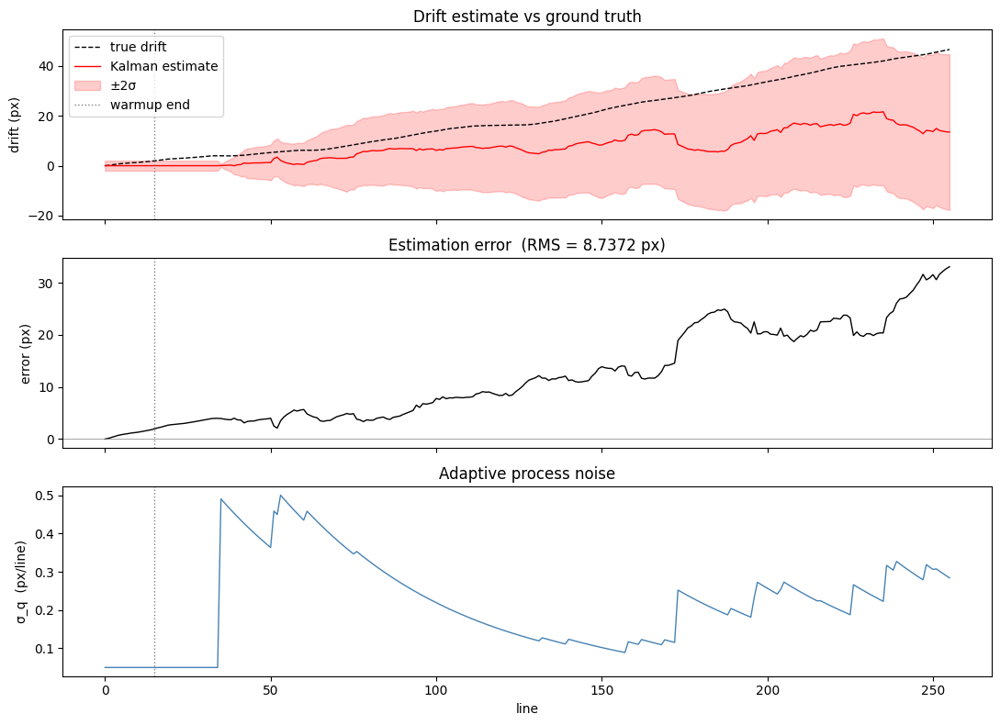

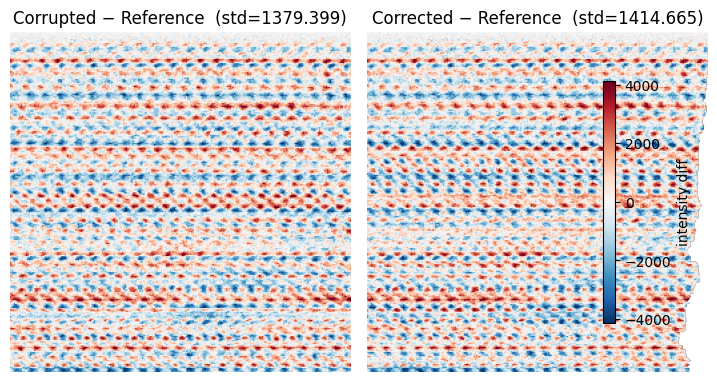

In [54]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates


# ── 1. SHIFT ESTIMATOR ────────────────────────────────────────────────────────

def estimate_shift(line_prev, line_curr,
                   search_center=0.0,
                   search_half=5.0):
    """
    Phase correlation + Gaussian peak fit.
    Hann apodization kills edge/periodicity artefacts.
    Constrained search window prevents lattice-period jumps.
    """
    n = len(line_prev)

    def _norm(x):
        x = x - x.mean()
        s = x.std()
        return x / s if s > 1e-10 else x

    window = np.hanning(n)
    a = _norm(line_prev) * window
    b = _norm(line_curr) * window

    Fa, Fb = np.fft.rfft(a), np.fft.rfft(b)
    cross  = Fa * np.conj(Fb)
    denom  = np.abs(cross)
    pc     = np.fft.irfft(np.where(denom > 1e-10, cross / denom, 0.0), n=n)
    pc     = np.fft.fftshift(pc)
    lags   = np.arange(n) - n // 2

    lo   = search_center - search_half
    hi   = search_center + search_half
    mask = (lags >= lo) & (lags <= hi)
    if mask.sum() < 3:
        mask = np.abs(lags) <= n // 4

    peak_idx    = int(np.argmax(np.where(mask, pc, -np.inf)))
    noise_floor = np.median(np.abs(pc[mask]))
    confidence  = float(pc[peak_idx] / (noise_floor + 1e-10))

    half_w     = 6
    lo_f, hi_f = max(peak_idx - half_w, 0), min(peak_idx + half_w + 1, n)
    fit_lags   = lags[lo_f:hi_f].astype(float)
    fit_vals   = pc[lo_f:hi_f]
    shift_int  = float(lags[peak_idx])
    shift_std  = float(search_half)

    try:
        def gaussian(x, center, sigma, amp, offset):
            return amp * np.exp(-0.5 * ((x - center) / sigma) ** 2) + offset

        popt, pcov = curve_fit(
            gaussian, fit_lags, fit_vals,
            p0=[shift_int, 2.0, float(pc[peak_idx]), float(noise_floor)],
            bounds=([shift_int - half_w, 0.3,  0.0, -np.inf],
                    [shift_int + half_w, half_w, np.inf, np.inf]),
            maxfev=400,
        )
        if np.sqrt(pcov[0, 0]) <= half_w:
            shift_int = float(popt[0])
            shift_std = float(popt[1])
    except (RuntimeError, ValueError):
        pass

    return shift_int, shift_std, confidence


# ── 2. PRIOR ESTIMATION FROM WARMUP LINES ────────────────────────────────────

def estimate_priors(warmup_lines, max_lag=None, verbose=True):
    n_warmup = len(warmup_lines)
    if max_lag is None:
        max_lag = max(2, n_warmup // 3)

    # ── pass 1: use highest lag for rough v0 — best SNR ──
    # at lag k_seed the shift is k_seed * v0 which is measurable even for slow drift
    k_seed = max(2, n_warmup // 2)
    pass1_shifts = []
    for i in range(n_warmup - k_seed):
        s, _, _ = estimate_shift(
            warmup_lines[i], warmup_lines[i + k_seed],
            search_center=0.0,
            search_half=min(k_seed * 2.0, 15.0),
        )
        pass1_shifts.append(s)

    v0_rough = float(np.median(pass1_shifts)) / k_seed   # per-line velocity

    # ── pass 2: all lags, window centered on v0_rough * k ──
    lags_all, shifts_all, stds_all = [], [], []

    for k in range(1, max_lag + 1):
        search_center = v0_rough * k
        search_half   = max(2.0, 3.0 * abs(v0_rough) * k)
        for i in range(n_warmup - k):
            s, std, _ = estimate_shift(
                warmup_lines[i], warmup_lines[i + k],
                search_center=search_center,
                search_half=search_half,
            )
            lags_all.append(k)
            shifts_all.append(s)
            stds_all.append(std)

    lags_all   = np.array(lags_all,   dtype=float)
    shifts_all = np.array(shifts_all, dtype=float)
    stds_all   = np.array(stds_all,   dtype=float)

    weights = 1.0 / np.maximum(stds_all ** 2, 1e-6)

    # WLS: shift = v * lag
    v0 = float(
        np.sum(weights * lags_all * shifts_all) /
        np.sum(weights * lags_all ** 2)
    )

    residuals            = shifts_all - v0 * lags_all
    normalised_residuals = residuals / np.sqrt(lags_all)
    sigma_q = float(np.clip(np.std(normalised_residuals), 0.005, 0.5))

    d0       = 0.0
    R_median = float(np.median(stds_all[lags_all == 1] ** 2))

    var_v0 = float(1.0 / np.sum(weights * lags_all ** 2))
    var_d0 = var_v0
    P0     = np.array([[var_d0, 0.0], [0.0, var_v0]])
    x0     = np.array([d0, v0])

    if verbose:
        print(f"Warmup prior estimation ({n_warmup} lines, max_lag={max_lag}):")
        print(f"  pass-1 rough v0   : {v0_rough:.5f} px/line  (median lag-1)")
        print(f"  measurements used : {len(shifts_all)}")
        print(f"  initial velocity  : v0      = {v0:.5f} px/line")
        print(f"  cumulative drift  : d0      = {d0:.4f} px")
        print(f"  process noise     : sigma_q = {sigma_q:.5f} px/line")
        print(f"  median obs noise  : R       = {R_median:.4f} px²")
        print(f"  std(d0) = {np.sqrt(var_d0):.4f} px,  "
              f"std(v0) = {np.sqrt(var_v0):.5f} px/line")

    return x0, P0, sigma_q, R_median


# ── 3. KALMAN FORWARD PASS ────────────────────────────────────────────────────

def build_Q(sigma_q):
    return np.array([[sigma_q**2 / 4,  sigma_q**2 / 2],
                     [sigma_q**2 / 2,  sigma_q**2]])


def kalman_forward(stream, n_lines,
                   n_warmup=15,
                   max_lag=None,
                   alpha_up=0.3,
                   alpha_down=0.02,
                   sigma_q_min=0.005,
                   sigma_q_max=0.5,
                   search_half_init=5.0,
                   search_half_min=2.0):
    """
    Forward Kalman filter with incremental observations.

    State:       x = [d, v]
    Transition:  d[n] = d[n-1] + v[n-1]
                 v[n] = v[n-1] + q
    Observation: z = shift(n, n-1) ≈ v[n-1]  →  H = [0, 1]

    Position d accumulates through the state transition itself —
    no explicit cumulative sum, so noise does not pile up over time.
    """
    F = np.array([[1., 1.], [0., 1.]])
    H = np.array([[0., 1.]])          # observe velocity from increment

    d_hat        = np.zeros(n_lines)
    x_hist       = np.zeros((n_lines, 2))
    P_hist       = np.zeros((n_lines, 2, 2))
    sigma_q_hist = np.zeros(n_lines)
    true_ux      = np.full(n_lines, np.nan)
    raw_lines    = []

    warmup_buffer = []
    x             = np.array([0., 0.])
    P             = np.eye(2)
    sigma_q       = 0.05
    prev_line     = None
    x_prev        = x.copy()

    for frame in stream:
        n    = frame['line_index']
        line = frame['line']
        raw_lines.append(line.copy())

        if 'ux_true' in frame:
            true_ux[n] = frame['ux_true']

        # ── warmup phase ──
        if n < n_warmup:
            warmup_buffer.append(line.copy())
            d_hat[n]        = 0.0
            x_hist[n]       = x
            P_hist[n]       = P
            sigma_q_hist[n] = sigma_q

            if n == n_warmup - 1:
                x0, P0, sigma_q, _ = estimate_priors(
                    warmup_buffer, max_lag=max_lag
                )
                x         = x0.copy()
                P         = P0.copy()
                prev_line = warmup_buffer[-1]

                print(f"  Kalman filter starting at line {n_warmup}\n")
            continue

        # ── predict first — use to constrain CC search ──
        Q      = build_Q(sigma_q)
        x_pred = F @ x
        P_pred = F @ P @ F.T + Q

        # search window centered on predicted velocity
        search_center = float(x_pred[1])
        search_half   = float(np.clip(
            2.0 * np.sqrt(P_pred[1, 1]),
            search_half_min,
            search_half_init,
        ))

        # ── measure increment ──
        shift, shift_std, _ = estimate_shift(
            prev_line, line,
            search_center=search_center,
            search_half=search_half,
        )
        R = shift_std ** 2

        # ── update: z = shift ≈ v ──
        z = np.array([shift])
        y = z - H @ x_pred
        S = H @ P_pred @ H.T + R
        K = (P_pred @ H.T).flatten() / float(S[0, 0])

        x_prev = x.copy()
        x      = x_pred + K * float(y[0])
        P      = (np.eye(2) - np.outer(K, H)) @ P_pred

        # ── adaptive sigma_q ──
        dv = abs(float(x[1]) - float(x_prev[1]))
        if dv > sigma_q:
            sigma_q = alpha_up   * dv          + (1 - alpha_up)   * sigma_q
        else:
            sigma_q = alpha_down * sigma_q_min + (1 - alpha_down) * sigma_q
        sigma_q = float(np.clip(sigma_q, sigma_q_min, sigma_q_max))

        d_hat[n]        = float(x[0])
        x_hist[n]       = x
        P_hist[n]       = P
        sigma_q_hist[n] = sigma_q
        prev_line       = line

    return d_hat, x_hist, P_hist, sigma_q_hist, true_ux, raw_lines


# ── 4. CORRECTION ─────────────────────────────────────────────────────────────

def apply_correction(raw_lines, drift_x):
    H   = len(raw_lines)
    W   = len(raw_lines[0])
    img = np.array(raw_lines, dtype=float)
    corrected = np.full((H, W), np.nan)
    cols = np.arange(W, dtype=float)

    for n in range(H):
        shifted_cols = cols + drift_x[n]
        valid  = (shifted_cols >= 0) & (shifted_cols <= W - 1)
        coords = np.array([np.full(W, float(n)), shifted_cols])
        row    = map_coordinates(img, coords, order=1, mode='constant', cval=np.nan)
        row[~valid] = np.nan
        corrected[n] = row

    return corrected


# ── 5. RUN ────────────────────────────────────────────────────────────────────

stream = corrupted_image_scan_stream(img_cor, true_ux=ux, true_uy=uy)

d_hat, x_hist, P_hist, sigma_q_hist, true_ux_arr, raw_lines = kalman_forward(
    stream, n_lines=len(img_cor),
    n_warmup=35,
    max_lag=None,
    alpha_up=0.5,
    alpha_down=0.02,
    sigma_q_min=0.005,
    sigma_q_max=0.5,
    search_half_init=5.0,
    search_half_min=2.0,
)

img_corrected = apply_correction(raw_lines, d_hat)


# ── 6. VISUALISATION ──────────────────────────────────────────────────────────

lines = np.arange(len(img_cor))
sigma = np.sqrt(P_hist[:, 0, 0])

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
axes[0].imshow(img_ref,       cmap='gray'); axes[0].set_title('Reference');          axes[0].axis('off')
axes[1].imshow(img_cor,       cmap='gray'); axes[1].set_title('Corrupted');          axes[1].axis('off')
axes[2].imshow(img_corrected, cmap='gray'); axes[2].set_title('Corrected (Kalman)'); axes[2].axis('off')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

axes[0].plot(lines, true_ux_arr, 'k--', lw=1, label='true drift')
axes[0].plot(lines, d_hat,       'r',   lw=1, label='Kalman estimate')
axes[0].fill_between(lines, d_hat - 2*sigma, d_hat + 2*sigma,
                     alpha=0.2, color='r', label='±2σ')
axes[0].axvline(n_warmup := 15, color='gray', lw=1, ls=':', label='warmup end')
axes[0].set_ylabel('drift (px)'); axes[0].legend()
axes[0].set_title('Drift estimate vs ground truth')

axes[1].plot(lines, true_ux_arr - d_hat, 'k', lw=1)
axes[1].axhline(0, color='gray', lw=0.5)
axes[1].axvline(15, color='gray', lw=1, ls=':')
axes[1].set_ylabel('error (px)')
axes[1].set_title(f'Estimation error  (RMS = {float(np.nanstd(true_ux_arr - d_hat)):.4f} px)')

axes[2].plot(lines, sigma_q_hist, color='steelblue', lw=1)
axes[2].axvline(15, color='gray', lw=1, ls=':')
axes[2].set_ylabel('σ_q  (px/line)'); axes[2].set_xlabel('line')
axes[2].set_title('Adaptive process noise')

plt.tight_layout(); plt.show()

diff_before = img_cor - img_ref
diff_after  = np.where(np.isnan(img_corrected), np.nan, img_corrected - img_ref)
vmax = float(np.nanstd(diff_before)) * 3

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(diff_before, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
axes[0].set_title(f'Corrupted − Reference  (std={float(np.nanstd(diff_before)):.3f})')
axes[0].axis('off')
im = axes[1].imshow(diff_after, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
axes[1].set_title(f'Corrected − Reference  (std={float(np.nanstd(diff_after)):.3f})')
axes[1].axis('off')
plt.colorbar(im, ax=axes.tolist(), shrink=0.7, label='intensity diff')
plt.subplots_adjust(wspace=0.05); plt.show()

Step 1 — Find the lattice frequencies
We need to know which FFT bin corresponds to the atomic lattice period. We compute the 1D power spectrum of every row and average them all together.

Step 2 — Measure velocity from the phase ramp

Step 4 — Apply the correction

Running Bragg phase-ramp drift estimation...

Lattice frequencies (k/W): ['22/256=0.0859', '43/256=0.1680']

  block [  0–  8]  v = -0.08422 px/line  ±0.03795  per-freq: ['-1.1604', '+0.1804']
  block [  8– 16]  v = -0.01303 px/line  ±0.04993  per-freq: ['-0.5455', '+0.0176']
  block [ 16– 24]  v = -0.08969 px/line  ±0.05717  per-freq: ['-0.9504', '+0.0340']
  block [ 24– 32]  v = +0.07039 px/line  ±0.03100  per-freq: ['-1.4560', '+0.1127']
  block [ 32– 40]  v = -0.02535 px/line  ±0.01732  per-freq: ['-1.2735', '+0.0633']
  block [ 40– 48]  v = +0.01406 px/line  ±0.04996  per-freq: ['-0.6589', '+0.0780']
  block [ 48– 56]  v = -0.17853 px/line  ±0.05008  per-freq: ['-0.8147', '+0.1680']
  block [ 56– 64]  v = -0.07040 px/line  ±0.02171  per-freq: ['-1.3076', '-0.0525']
  block [ 64– 72]  v = +0.02271 px/line  ±0.03621  per-freq: ['-1.0356', '+0.1980']
  block [ 72– 80]  v = -0.03840 px/line  ±0.04234  per-freq: ['-0.2692', '+0.2273']
  block [ 80– 88]  v = +0.16777 px/line  ±0.01972  

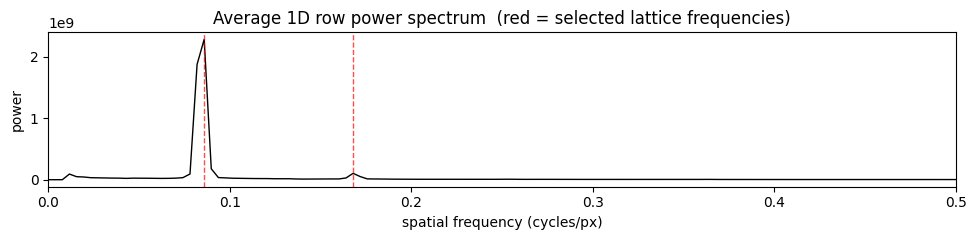

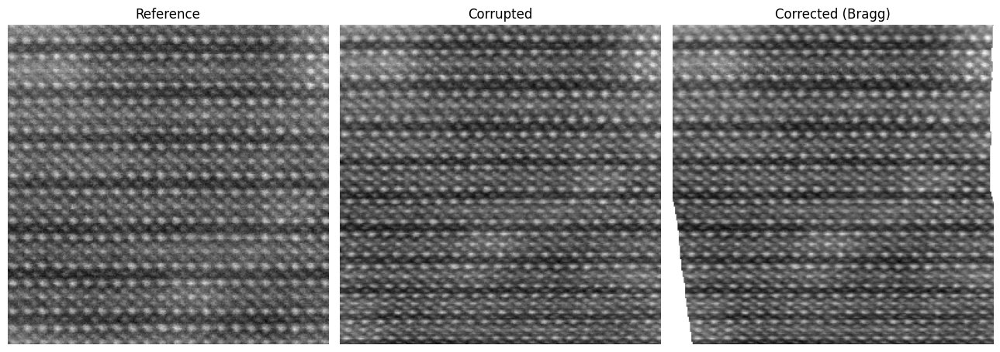

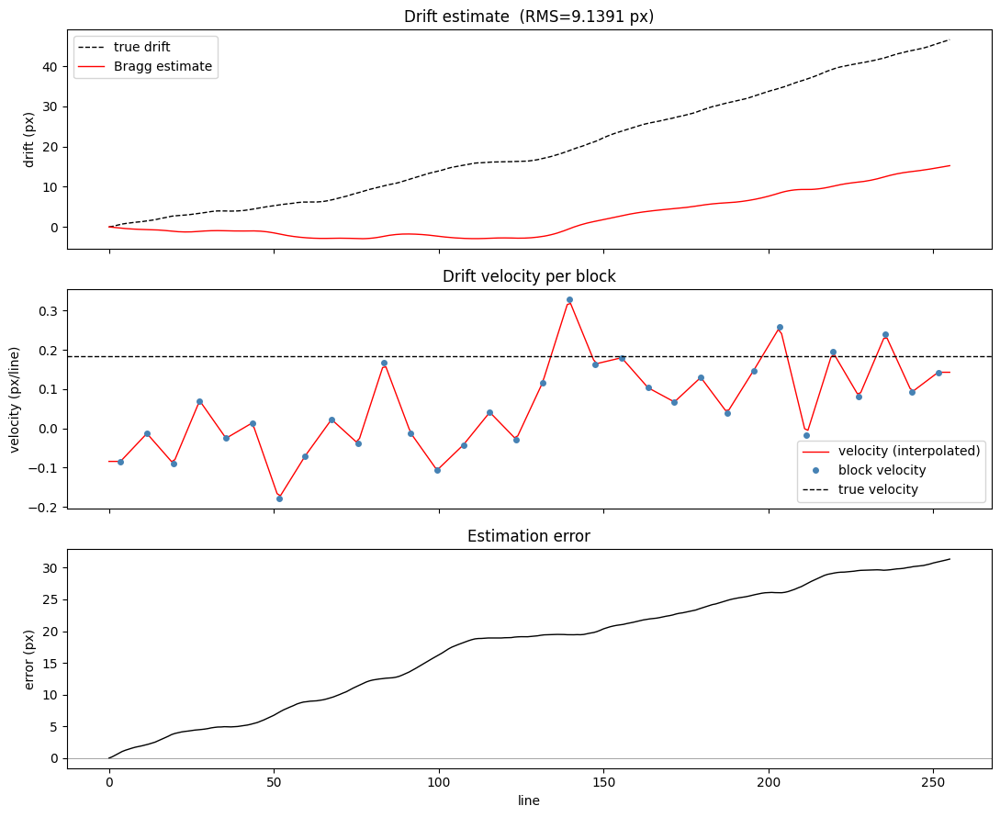

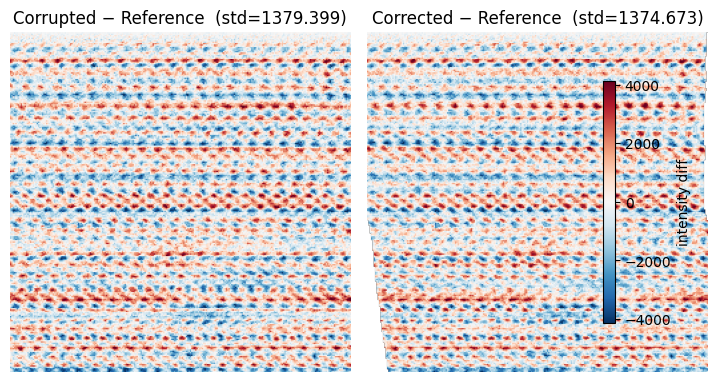

In [72]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates


# ── 1. FIND LATTICE FREQUENCIES FROM 1D ROW SPECTRUM ────────────────────────

def find_lattice_frequencies(block, n_freqs=3, min_dist=3):
    """
    Find dominant lattice frequencies from the AVERAGE 1D power spectrum
    of all rows. Averaging over rows cancels phase variations from drift
    but preserves the lattice frequencies.

    Returns list of integer FFT column indices (positive frequencies only).
    """
    H, W = block.shape

    # average 1D power spectrum across all rows
    ps1d = np.zeros(W // 2 + 1)
    for n in range(H):
        row_fft = np.fft.rfft(block[n] * np.hanning(W))
        ps1d   += np.abs(row_fft) ** 2
    ps1d /= H

    # suppress DC
    ps1d[:min_dist] = 0

    # find peaks
    freqs, ps_work = [], ps1d.copy()
    for _ in range(n_freqs):
        k = int(np.argmax(ps_work))
        freqs.append(k)
        ps_work[max(0, k - min_dist):min(len(ps_work), k + min_dist)] = 0

    return freqs, ps1d


# ── 2. VELOCITY FROM PHASE RAMP AT LATTICE FREQUENCIES ──────────────────────

def velocity_from_phase_ramp(block, freqs, verbose=False):
    """
    For each lattice frequency k, measure the phase of the 1D row FFT
    at column k for every row. The x-drift d(n) introduces:
        phi(n) = phi_0 - 2*pi*(k/W)*d(n)
    so fitting a linear ramp gives:
        v = -slope / (2*pi*(k/W))

    Returns weighted mean velocity and per-frequency estimates.
    """
    H, W = block.shape
    ns   = np.arange(H, dtype=float)

    v_ests, v_stds = [], []

    for k in freqs:
        kx = k / W
        if kx < 1e-6:
            continue

        phases = np.unwrap([
            np.angle(np.fft.rfft(block[n])[k])
            for n in range(H)
        ])

        try:
            coeffs, cov = np.polyfit(ns, phases, 1, cov=True)
            slope = coeffs[0]
            v     = slope / (2 * np.pi * kx)
            v_s   = float(np.sqrt(cov[0, 0])) / (2 * np.pi * kx)
            v_ests.append(v)
            v_stds.append(abs(v_s))

            if verbose:
                print(f"  k={k:3d}  kx={kx:.4f}  "
                      f"slope={slope:+.5f}  v={v:+.5f} ± {abs(v_s):.5f}")
        except (np.linalg.LinAlgError, ValueError):
            continue

    if not v_ests:
        return 0.0, np.inf, []

    v_ests = np.array(v_ests)
    v_stds = np.array(v_stds)
    w      = 1.0 / np.maximum(v_stds ** 2, 1e-10)
    v_est  = float(np.sum(w * v_ests) / np.sum(w))
    v_std  = float(np.sqrt(1.0 / np.sum(w)))

    return v_est, v_std, v_ests.tolist()


# ── 3. BRAGG DRIFT ESTIMATOR ─────────────────────────────────────────────────

def bragg_correct(raw_lines, n_lines,
                  block_size=16,
                  block_step=8,
                  n_freqs=3,
                  verbose=True):
    """
    Estimate drift from phase ramps at lattice frequencies.

    1. Average 1D power spectrum → lattice frequencies (drift-invariant)
    2. Per-row phase at those frequencies → phase ramp → velocity
    3. Interpolate block velocities → integrate → drift position
    """
    H  = n_lines
    W  = len(raw_lines[0])
    img = np.array(raw_lines, dtype=float)

    # find lattice frequencies from the full image average (most stable)
    global_freqs, ps1d = find_lattice_frequencies(img, n_freqs=n_freqs)
    if verbose:
        kxs = [f'{k}/{W}={k/W:.4f}' for k in global_freqs]
        print(f"Lattice frequencies (k/W): {kxs}\n")

    block_centers = []
    block_v_ests  = []
    block_v_stds  = []

    for start in range(0, H - block_size + 1, block_step):
        end   = start + block_size
        block = img[start:end]

        v_est, v_std, peak_vs = velocity_from_phase_ramp(
            block, global_freqs, verbose=False
        )

        center = (start + end - 1) / 2.0
        block_centers.append(center)
        block_v_ests.append(v_est)
        block_v_stds.append(v_std)

        if verbose:
            print(f"  block [{start:3d}–{end:3d}]  "
                  f"v = {v_est:+.5f} px/line  ±{v_std:.5f}  "
                  f"per-freq: {[f'{v:+.4f}' for v in peak_vs]}")

    block_centers = np.array(block_centers)
    block_v_ests  = np.array(block_v_ests)
    block_v_stds  = np.array(block_v_stds)

    # interpolate velocity to all lines
    lines = np.arange(H, dtype=float)
    v_hat = np.interp(lines, block_centers, block_v_ests,
                      left=block_v_ests[0], right=block_v_ests[-1])

    # integrate → drift position, anchored at 0
    d_hat = np.cumsum(v_hat)
    d_hat -= d_hat[0]

    return d_hat, v_hat, block_centers, block_v_ests, block_v_stds, ps1d, global_freqs


# ── 4. CORRECTION ─────────────────────────────────────────────────────────────

def apply_correction(raw_lines, drift_x):
    H   = len(raw_lines)
    W   = len(raw_lines[0])
    img = np.array(raw_lines, dtype=float)
    corrected = np.full((H, W), np.nan)
    cols = np.arange(W, dtype=float)
    for n in range(H):
        shifted_cols = cols - drift_x[n]
        valid  = (shifted_cols >= 0) & (shifted_cols <= W - 1)
        coords = np.array([np.full(W, float(n)), shifted_cols])
        row    = map_coordinates(img, coords, order=1,
                                 mode='constant', cval=np.nan)
        row[~valid] = np.nan
        corrected[n] = row
    return corrected


# ── 5. RUN ───────────────────────────────────────────────────────────────────

stream    = corrupted_image_scan_stream(img_cor, true_ux=ux, true_uy=uy)
raw_lines = [frame['line'].astype(float) for frame in stream]
true_ux_arr = ux.copy()

print("Running Bragg phase-ramp drift estimation...\n")

(d_hat, v_hat, b_centers, b_v_ests,
 b_v_stds, ps1d, lattice_freqs) = bragg_correct(
    raw_lines, n_lines=len(raw_lines),
    block_size=8,
    block_step=8,
    n_freqs=2,
)

img_corrected = apply_correction(raw_lines, d_hat)


# ── 6. VISUALISATION ─────────────────────────────────────────────────────────

lines = np.arange(len(raw_lines))

# 1D power spectrum with lattice frequencies marked
fig, ax = plt.subplots(figsize=(10, 2.5))
freqs_axis = np.arange(len(ps1d)) / len(raw_lines[0])
ax.plot(freqs_axis, ps1d, 'k', lw=1)
for k in lattice_freqs:
    ax.axvline(k / len(raw_lines[0]), color='r', lw=1, ls='--', alpha=0.7)
ax.set_xlabel('spatial frequency (cycles/px)')
ax.set_ylabel('power')
ax.set_title('Average 1D row power spectrum  (red = selected lattice frequencies)')
ax.set_xlim(0, 0.5)
plt.tight_layout(); plt.show()

# images
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
axes[0].imshow(img_ref,       cmap='gray'); axes[0].set_title('Reference');        axes[0].axis('off')
axes[1].imshow(img_cor,       cmap='gray'); axes[1].set_title('Corrupted');         axes[1].axis('off')
axes[2].imshow(img_corrected, cmap='gray'); axes[2].set_title('Corrected (Bragg)'); axes[2].axis('off')
plt.tight_layout(); plt.show()

# drift + velocity + error
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)

axes[0].plot(lines, true_ux_arr, 'k--', lw=1, label='true drift')
axes[0].plot(lines, d_hat,       'r',   lw=1, label='Bragg estimate')
axes[0].set_ylabel('drift (px)'); axes[0].legend()
axes[0].set_title(f'Drift estimate  (RMS={float(np.nanstd(true_ux_arr - d_hat)):.4f} px)')

axes[1].plot(lines, v_hat, 'r', lw=1, label='velocity (interpolated)')
axes[1].plot(b_centers, b_v_ests, 'o', ms=4, color='steelblue', label='block velocity')
axes[1].axhline(np.mean(np.diff(true_ux_arr)), color='k', lw=1, ls='--', label='true velocity')
axes[1].set_ylabel('velocity (px/line)'); axes[1].legend()
axes[1].set_title('Drift velocity per block')

axes[2].plot(lines, true_ux_arr - d_hat, 'k', lw=1)
axes[2].axhline(0, color='gray', lw=0.5)
axes[2].set_ylabel('error (px)'); axes[2].set_xlabel('line')
axes[2].set_title('Estimation error')

plt.tight_layout(); plt.show()

# difference images
diff_before = img_cor - img_ref
diff_after  = np.where(np.isnan(img_corrected), np.nan, img_corrected - img_ref)
vmax = float(np.nanstd(diff_before)) * 3
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(diff_before, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
axes[0].set_title(f'Corrupted − Reference  (std={float(np.nanstd(diff_before)):.3f})')
axes[0].axis('off')
im = axes[1].imshow(diff_after, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
axes[1].set_title(f'Corrected − Reference  (std={float(np.nanstd(diff_after)):.3f})')
axes[1].axis('off')
plt.colorbar(im, ax=axes.tolist(), shrink=0.7, label='intensity diff')
plt.subplots_adjust(wspace=0.05); plt.show()

In [79]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates


# ══════════════════════════════════════════════════════════════════════════════
# 2D BRAGG PHASE-RAMP DRIFT CORRECTOR  (x and y drift)
# ══════════════════════════════════════════════════════════════════════════════
#
# X-DRIFT and Y-DRIFT are fundamentally different signals:
#
# X-drift shifts each row sideways. In the 1D row FFT, this appears as
# a phase ramp: phi(n) = phi_0 + 2*pi*kx*vx*n. The slope gives vx directly.
# We use the AVERAGE 1D row power spectrum to find kx — averaging over rows
# cancels drift-induced phase variations and leaves only the lattice peaks.
#
# Y-drift compresses or stretches the slow-scan axis. Each row n lands at
# y = n + vy*n instead of y = n. This does NOT create a phase ramp in the
# column direction — it changes the apparent PERIOD of the y-lattice.
# We detect it by tracking the phase of the y-lattice frequency in the
# average column profile across blocks.


# ── X-DRIFT: LATTICE FREQUENCIES FROM AVERAGE 1D ROW SPECTRUM ────────────────

def find_x_lattice_freqs(img, n_freqs=3, min_dist=3):
    """
    Average 1D power spectrum across all rows → find x-lattice frequencies.
    Drift-invariant: averaging cancels phase shifts, keeps amplitude peaks.
    """
    H, W  = img.shape
    ps1d  = np.zeros(W // 2 + 1)
    for n in range(H):
        ps1d += np.abs(np.fft.rfft(img[n] * np.hanning(W))) ** 2
    ps1d /= H
    ps1d[:min_dist] = 0

    freqs, ps_work = [], ps1d.copy()
    for _ in range(n_freqs):
        k = int(np.argmax(ps_work))
        freqs.append(k)
        ps_work[max(0, k - min_dist):min(len(ps_work), k + min_dist)] = 0

    return freqs, ps1d


# ── X-DRIFT: VELOCITY FROM PHASE RAMP ────────────────────────────────────────

def estimate_vx_from_phase_ramp(block, x_freqs):
    """
    For each x-lattice frequency k, extract per-row phase from 1D row FFT.
    Fit linear ramp phi(n) = phi_0 + 2*pi*(k/W)*vx*n → vx = slope/(2*pi*kx).
    """
    H, W = block.shape
    ns   = np.arange(H, dtype=float)
    v_ests, v_stds = [], []

    for k in x_freqs:
        kx = k / W
        if kx < 1e-6:
            continue

        phases = np.unwrap([
            np.angle(np.fft.rfft(block[n] * np.hanning(W))[k])
            for n in range(H)
        ])

        try:
            coeffs, cov = np.polyfit(ns, phases, 1, cov=True)
            v   = coeffs[0] / (2 * np.pi * kx)
            v_s = float(np.sqrt(cov[0, 0])) / (2 * np.pi * kx)
            v_ests.append(v); v_stds.append(abs(v_s))
        except (np.linalg.LinAlgError, ValueError):
            continue

    if not v_ests:
        return 0.0, np.inf

    v_ests = np.array(v_ests); v_stds = np.array(v_stds)
    w = 1.0 / np.maximum(v_stds ** 2, 1e-10)
    return float(np.sum(w * v_ests) / np.sum(w)), float(np.sqrt(1.0 / np.sum(w)))


# ── Y-DRIFT: LATTICE FREQUENCY FROM AVERAGE COLUMN PROFILE ───────────────────

def find_y_lattice_freqs(img, n_freqs=2, min_dist=3):
    """
    Average all columns together → 1D profile along y-axis.
    Find dominant frequencies in this profile.
    The y-lattice period shows up as a strong peak.
    """
    H, W  = img.shape
    col_profile = img.mean(axis=1)
    col_profile -= col_profile.mean()

    ps_col = np.abs(np.fft.rfft(col_profile * np.hanning(H))) ** 2
    ps_col[:min_dist] = 0

    freqs, ps_work = [], ps_col.copy()
    for _ in range(n_freqs):
        if ps_work.max() <= 0:
            break
        k = int(np.argmax(ps_work))
        freqs.append(k)
        ps_work[max(0, k - min_dist):min(len(ps_work), k + min_dist)] = 0

    if not freqs:
        freqs = [min_dist]   # fallback: first non-DC bin

    return freqs, ps_col, col_profile


# ── Y-DRIFT: VELOCITY FROM Y-LATTICE FREQUENCY SHIFT ────────────────────────
#
# In a line-by-line scan, rows are always stored at integer indices 0,1,2,...
# Y-drift does NOT create a phase ramp — instead it changes the APPARENT
# y-lattice period. If the sample drifts at vy px/line in y, rows are
# compressed (or stretched), so the apparent y-lattice frequency shifts:
#
#   k_apparent = k_true * (1 + vy)   →   vy = k_apparent / k_true - 1
#
# We measure this by finding the y-lattice peak position with subpixel
# accuracy in each block's average column profile, then tracking how that
# frequency changes across blocks.

def find_peak_subpixel(ps, k_int):
    """Parabolic subpixel refinement around integer peak k_int."""
    if 1 <= k_int <= len(ps) - 2:
        y0, y1, y2 = ps[k_int-1], ps[k_int], ps[k_int+1]
        denom = 2 * (2*y1 - y0 - y2)
        if abs(denom) > 1e-12:
            return k_int + (y0 - y2) / denom
    return float(k_int)


def estimate_vy_from_frequency_shift(col_profiles, y_freqs_ref, H_block):
    """
    For each block, find the y-lattice frequency with subpixel accuracy.
    Compare to the reference frequency (from the first block).
    vy_block = k_apparent / k_ref - 1 (compression ratio).
    Fit a linear trend across blocks to get a smooth vy estimate.

    col_profiles  : list of 1D arrays (one per block), mean(block, axis=1)
    y_freqs_ref   : reference y-lattice bin indices (from full image average)
    H_block       : rows per block
    """
    n_blocks = len(col_profiles)
    if n_blocks < 3:
        return 0.0, np.inf, []

    block_ns = np.arange(n_blocks, dtype=float)
    v_ests, v_stds = [], []

    for k_ref in y_freqs_ref:
        if k_ref < 2:
            continue

        # find subpixel peak position in each block's column spectrum
        k_apparent = []
        for prof in col_profiles:
            ps = np.abs(np.fft.rfft(prof * np.hanning(len(prof)))) ** 2
            # search near k_ref
            search = slice(max(0, k_ref-3), min(len(ps), k_ref+4))
            local_ps = ps[search]
            local_peak = int(np.argmax(local_ps)) + max(0, k_ref-3)
            k_sub = find_peak_subpixel(ps, local_peak)
            k_apparent.append(k_sub)

        k_apparent = np.array(k_apparent)

        # vy_block = k_apparent / k_ref - 1
        # this is the fractional compression per block
        vy_blocks = k_apparent / k_ref - 1.0

        # fit linear trend: vy changes slowly with block index
        try:
            coeffs, cov = np.polyfit(block_ns, vy_blocks, 0, cov=True)
            # constant fit (mean vy) — vy is approximately constant
            # for random-walk drift the mean over the scan is meaningful
            v_mean = float(coeffs[0])
            v_std  = float(np.sqrt(cov[0, 0]))
            v_ests.append(v_mean)
            v_stds.append(v_std)
        except (np.linalg.LinAlgError, ValueError):
            continue

    if not v_ests:
        return 0.0, np.inf, []

    v_ests = np.array(v_ests); v_stds = np.array(v_stds)
    w = 1.0 / np.maximum(v_stds ** 2, 1e-10)
    return (float(np.sum(w * v_ests) / np.sum(w)),
            float(np.sqrt(1.0 / np.sum(w))),
            v_ests.tolist())


# ── ATOM SHAPE: ESTIMATE SIGMA ────────────────────────────────────────────────

def estimate_atom_sigma(x_freqs, ps1d, W):
    """
    Fit Gaussian envelope to Bragg peak amplitudes → atom radius sigma.
    Round atoms: A(k) ~ exp(-2*pi^2*sigma^2*k^2). Stronger peaks = more weight.
    """
    k2_vals  = np.array([(k/W)**2 for k in x_freqs])
    amp_vals = np.array([np.sqrt(float(ps1d[k])) for k in x_freqs])

    sigma_px = 1.0
    try:
        valid = amp_vals > 0
        if valid.sum() >= 2:
            coeffs = np.polyfit(k2_vals[valid], np.log(amp_vals[valid] + 1e-10), 1)
            b = -coeffs[0]
            if b > 0:
                sigma_px = float(np.sqrt(b / (2 * np.pi**2)))
    except (np.linalg.LinAlgError, ValueError):
        pass

    weights = np.array([
        np.exp(-2 * np.pi**2 * sigma_px**2 * (k/W)**2)
        for k in x_freqs
    ])
    return sigma_px, weights


# ── MAIN ESTIMATOR ────────────────────────────────────────────────────────────

def bragg_correct_2d(raw_lines, n_lines,
                     block_size=32, block_step=8,
                     n_x_freqs=3, n_y_freqs=2,
                     verbose=True):
    H   = n_lines
    W   = len(raw_lines[0])
    img = np.array(raw_lines, dtype=float)

    x_freqs, ps1d          = find_x_lattice_freqs(img, n_freqs=n_x_freqs)
    y_freqs, ps_col, _     = find_y_lattice_freqs(img, n_freqs=n_y_freqs)
    sigma_px, x_weights    = estimate_atom_sigma(x_freqs, ps1d, W)

    if verbose:
        print(f"Atom radius: sigma = {sigma_px:.2f} px")
        print(f"X lattice freqs: {x_freqs}  (kx = {[f'{k/W:.4f}' for k in x_freqs]})")
        print(f"Y lattice freqs: {y_freqs}  (ky = {[f'{k/H:.4f}' for k in y_freqs]})\n")

    b_centers, b_vx_ests, b_vx_stds, col_profiles = [], [], [], []

    for start in range(0, H - block_size + 1, block_step):
        end   = start + block_size
        block = img[start:end]

        vx, vx_std = estimate_vx_from_phase_ramp(block, x_freqs)

        b_centers.append((start + end - 1) / 2.0)
        b_vx_ests.append(vx); b_vx_stds.append(vx_std)
        col_profiles.append(block.mean(axis=1))

        if verbose:
            print(f"  block [{start:3d}–{end:3d}]  vx={vx:+.5f}±{vx_std:.5f} px/line")

    b_centers = np.array(b_centers)
    b_vx_ests = np.array(b_vx_ests)

    vy, vy_std, _ = estimate_vy_from_frequency_shift(col_profiles, y_freqs, block_size)
    if verbose:
        print(f"\n  vy (global) = {vy:+.5f} ± {vy_std:.5f} px/line")

    lines  = np.arange(H, dtype=float)
    vx_hat = np.interp(lines, b_centers, b_vx_ests,
                       left=b_vx_ests[0], right=b_vx_ests[-1])
    vy_hat = np.full(H, vy)

    dx_hat = np.cumsum(vx_hat); dx_hat -= dx_hat[0]
    dy_hat = np.cumsum(vy_hat); dy_hat -= dy_hat[0]

    return (dx_hat, dy_hat, vx_hat, vy_hat,
            b_centers, b_vx_ests, sigma_px,
            ps1d, ps_col, x_freqs, y_freqs)


# ── CORRECTION ────────────────────────────────────────────────────────────────

def apply_correction_2d(raw_lines, dx, dy):
    H   = len(raw_lines)
    W   = len(raw_lines[0])
    img = np.array(raw_lines, dtype=float)
    corrected = np.full((H, W), np.nan)
    cols = np.arange(W, dtype=float)

    for n in range(H):
        row_coords = np.full(W, float(n) - dy[n])
        col_coords = cols - dx[n]
        valid = ((row_coords >= 0) & (row_coords <= H - 1) &
                 (col_coords >= 0) & (col_coords <= W - 1))
        coords = np.array([row_coords, col_coords])
        row    = map_coordinates(img, coords, order=1,
                                 mode='constant', cval=np.nan)
        row[~valid] = np.nan
        corrected[n] = row

    return corrected


# ── RUN ───────────────────────────────────────────────────────────────────────

stream    = corrupted_image_scan_stream(img_cor, true_ux=ux, true_uy=uy)
raw_lines = [frame['line'].astype(float) for frame in stream]
true_ux_arr = ux.copy()
true_uy_arr = uy.copy()

print("Running 2D Bragg drift estimation...\n")

(dx_hat, dy_hat, vx_hat, vy_hat,
 b_centers, b_vx_ests, sigma_px,
 ps1d, ps_col, x_freqs, y_freqs) = bragg_correct_2d(
    raw_lines, n_lines=len(raw_lines),
    block_size=32, block_step=8,
    n_x_freqs=3, n_y_freqs=2,
)

img_corrected = apply_correction_2d(raw_lines, dx_hat, dy_hat)


# ── VISUALISATION ─────────────────────────────────────────────────────────────

lines = np.arange(len(raw_lines))
W_img = len(raw_lines[0])
H_img = len(raw_lines)

fig, axes = plt.subplots(1, 2, figsize=(13, 2.5))
freqs_x = np.arange(len(ps1d)) / W_img
axes[0].plot(freqs_x, ps1d, 'k', lw=1)
for k in x_freqs:
    axes[0].axvline(k / W_img, color='r', lw=1, ls='--', alpha=0.7)
axes[0].set_title('Avg row spectrum  (x-lattice, red = selected)')
axes[0].set_xlabel('cycles/px'); axes[0].set_xlim(0, 0.5)

freqs_y = np.arange(len(ps_col)) / H_img
axes[1].plot(freqs_y, ps_col, 'k', lw=1)
for k in y_freqs:
    axes[1].axvline(k / H_img, color='b', lw=1, ls='--', alpha=0.7)
axes[1].set_title('Avg column spectrum  (y-lattice, blue = selected)')
axes[1].set_xlabel('cycles/row'); axes[1].set_xlim(0, 0.5)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
axes[0].imshow(img_ref,       cmap='gray'); axes[0].set_title('Reference');           axes[0].axis('off')
axes[1].imshow(img_cor,       cmap='gray'); axes[1].set_title('Corrupted');            axes[1].axis('off')
axes[2].imshow(img_corrected, cmap='gray'); axes[2].set_title('Corrected (2D Bragg)'); axes[2].axis('off')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)

axes[0, 0].plot(lines, true_ux_arr, 'k--', lw=1, label='true')
axes[0, 0].plot(lines, dx_hat,      'r',   lw=1, label='estimate')
axes[0, 0].set_ylabel('drift x (px)'); axes[0, 0].legend()
axes[0, 0].set_title(f'X drift  (RMS={float(np.nanstd(true_ux_arr - dx_hat)):.4f} px)')

axes[0, 1].plot(lines, true_uy_arr, 'k--', lw=1, label='true')
axes[0, 1].plot(lines, dy_hat,      'b',   lw=1, label='estimate')
axes[0, 1].set_ylabel('drift y (px)'); axes[0, 1].legend()
axes[0, 1].set_title(f'Y drift  (RMS={float(np.nanstd(true_uy_arr - dy_hat)):.4f} px)')

axes[1, 0].plot(lines, vx_hat, 'r', lw=1, label='vx interpolated')
axes[1, 0].plot(b_centers, b_vx_ests, 'o', ms=4, color='steelblue')
axes[1, 0].axhline(np.mean(np.diff(true_ux_arr)), color='k', lw=1, ls='--', label='true vx')
axes[1, 0].set_ylabel('vx (px/line)'); axes[1, 0].legend()
axes[1, 0].set_xlabel('line'); axes[1, 0].set_title('X velocity per block')

axes[1, 1].plot(lines, vy_hat, 'b', lw=1, label='vy (constant)')
axes[1, 1].axhline(np.mean(np.diff(true_uy_arr)), color='k', lw=1, ls='--', label='true vy')
axes[1, 1].set_ylabel('vy (px/line)'); axes[1, 1].legend()
axes[1, 1].set_xlabel('line'); axes[1, 1].set_title('Y velocity (global estimate)')

plt.tight_layout(); plt.show()

diff_before = img_cor - img_ref
diff_after  = np.where(np.isnan(img_corrected), np.nan, img_corrected - img_ref)
vmax = float(np.nanstd(diff_before)) * 3
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(diff_before, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
axes[0].set_title(f'Corrupted − Reference  (std={float(np.nanstd(diff_before)):.3f})')
axes[0].axis('off')
im = axes[1].imshow(diff_after, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
axes[1].set_title(f'Corrected − Reference  (std={float(np.nanstd(diff_after)):.3f})')
axes[1].axis('off')
plt.colorbar(im, ax=axes.tolist(), shrink=0.7, label='intensity diff')
plt.subplots_adjust(wspace=0.05); plt.show()

print(f"\nSummary:")
print(f"  Atom radius : {sigma_px:.2f} px")
print(f"  X drift RMS : {float(np.nanstd(true_ux_arr - dx_hat)):.4f} px")
print(f"  Y drift RMS : {float(np.nanstd(true_uy_arr - dy_hat)):.4f} px")

Running 2D Bragg drift estimation...

Atom radius: sigma = 0.87 px
X lattice freqs: [22, 43, 3]  (kx = ['0.0859', '0.1680', '0.0117'])
Y lattice freqs: [29, 9]  (ky = ['0.1133', '0.0352'])

  block [  0– 32]  vx=+0.01922±0.00753 px/line
  block [  8– 40]  vx=+0.01373±0.00738 px/line
  block [ 16– 48]  vx=+0.01456±0.00593 px/line
  block [ 24– 56]  vx=+0.01525±0.00608 px/line
  block [ 32– 64]  vx=+0.00793±0.00702 px/line
  block [ 40– 72]  vx=+0.01912±0.00742 px/line
  block [ 48– 80]  vx=+0.01613±0.00936 px/line
  block [ 56– 88]  vx=+0.05007±0.00947 px/line
  block [ 64– 96]  vx=+0.15096±0.00586 px/line
  block [ 72–104]  vx=+0.16972±0.00722 px/line
  block [ 80–112]  vx=+0.12651±0.00766 px/line
  block [ 88–120]  vx=-0.09346±0.00993 px/line
  block [ 96–128]  vx=-0.16172±0.01035 px/line
  block [104–136]  vx=-0.03321±0.00660 px/line
  block [112–144]  vx=-0.06244±0.01192 px/line
  block [120–152]  vx=+0.04982±0.01016 px/line
  block [128–160]  vx=+0.17858±0.00750 px/line
  block [13

ValueError: attempt to get argmax of an empty sequence

## 9. Optional Demo

This cell visualizes how the corrupted image is revealed during acquisition.

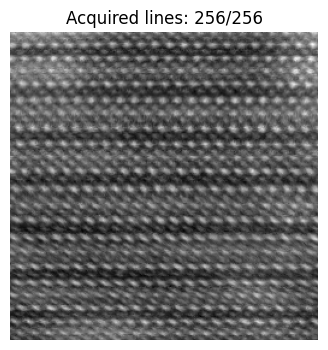

In [11]:
stream = corrupted_image_scan_stream(img_cor)

for _ in range(len(img_cor)):
    frame = next(stream)
    clear_output(wait=True)
    plt.figure(figsize=(4, 4))
    plt.imshow(frame["partial_image"], cmap="gray")
    plt.title(f"Acquired lines: {frame['line_index'] + 1}/{len(img_cor)}")
    plt.axis("off")
    plt.show()
    time.sleep(0.05)
